# Watermelon photo and knock-sound features, step by step
This notebook turns watermelon photos and knock recordings into numbers for your sheet. Each section does **one step** on **one example**, shows what the code found, then the last sections run it on everything and build the table.

**To run it:** put the photos in `photos/` and the knock recordings in `audio/`, both next to this notebook, then run the cells top to bottom (Shift+Enter). The first cell installs the packages. Everything is local — no Colab, no Drive.

* **Steps 1–15 — photos.** Step 2 writes normalised copies into `prepared/`; step 14 builds the per-melon photo table.
* **Steps 16–21 — knock sounds.** Step 20 merges the audio features in.
* **Step 22 — the training file.**

Either half runs without the other: with no `audio/` folder, steps 16–21 report "no audio" and the photo table is still written.

Two files come out, and they are not interchangeable:

| file | what it is |
| --- | --- |
| `watermelon_features.csv` | **for reading.** Everything, including diagnostics, the variety and all three raw Brix readings. Not safe to train on — `Brix sum` is the mean of the other three, so a model handed all four just learns the arithmetic. |
| `watermelon_training.csv` | **for training.** Predicts `brix_mean` from the 9 photo features and the 3 knock features. The target's components, both identifiers (`Name`, `melon_id`), the variety (`type`) and the recording diagnostics are all excluded; column names are cleaned. `watermelon_training_schema.json` beside it lists the features and what was dropped and why. |

Two things to know before you read the photo code:
* An image is a grid of pixels. Every pixel has three numbers. We convert them to **CIELAB** (L\*, a\*, b\*) because it separates *how bright* a pixel is (L\*) from *what colour* it is (a\*: green↔red, b\*: blue↔yellow). That makes "is this pixel yellow?" a simple `b > 38` test.
* All the photo thresholds live in one dictionary `T`, so you can change a number and re-run to see what happens.

## 0. Setup
This notebook runs on your **local Python environment** — no Google Colab and no Google Drive.

The first cell below installs every package the notebook needs, into whichever Python is running this kernel. Run it once; re-running is harmless (pip just reports "already satisfied").

The second cell does the imports and sets the three folders everything else uses:

| name | folder | what it is |
| --- | --- | --- |
| `PHOTO_DIR` | `photos/` | **your** photos. Read-only — the notebook never writes here. |
| `PREP_DIR` | `prepared/` | copies the notebook makes in step 2: rotation fixed, resized to 2576 px wide, renamed per melon. Every later photo step reads from here. |
| `AUDIO_DIR` | `audio/` | **your** knock recordings (steps 16–21). Read-only. |

All three are relative to the folder holding this notebook, so `photos/` means `D:\Watermelon\photos`. Change them if your files live somewhere else.

In [1]:
import sys, subprocess

# opencv-python 5 needs numpy 2, which breaks scipy; keep both pinned
REQUIREMENTS = [
    'numpy<2',
    'opencv-python<5',
    'pandas',
    'scipy',
    'matplotlib',
    'pillow',
    'pillow-heif',
    'librosa',
    'av',
]

print('installing into:', sys.executable)
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q',
                       '--no-warn-script-location', *REQUIREMENTS])
print('\ndone - if anything was newly installed, restart the kernel, then carry on below.')

installing into: C:\Users\napat\AppData\Local\Programs\Python\Python311\python.exe



done - if anything was newly installed, restart the kernel, then carry on below.


In [2]:
import os, io, glob, math, sys
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import pillow_heif; pillow_heif.register_heif_opener()

PHOTO_DIR = Path('photos')
PREP_DIR  = Path('prepared')
AUDIO_DIR = Path('audio')
PREP_DIR.mkdir(exist_ok=True)

def imread(path):
    """cv2.imread that also copes with Windows paths containing non-ASCII characters."""
    buf = np.fromfile(str(path), dtype=np.uint8)
    im = cv2.imdecode(buf, cv2.IMREAD_COLOR)
    if im is None:
        raise FileNotFoundError(f'could not decode image: {path}')
    return im

plt.rcParams['figure.dpi'] = 90
def show(img, title='', cmap=None, size=6):
    plt.figure(figsize=(size, size*img.shape[0]/img.shape[1])); plt.title(title); plt.axis('off')
    plt.imshow(img if img.ndim == 2 else cv2.cvtColor(img, cv2.COLOR_BGR2RGB), cmap=cmap); plt.show()

print('python     :', sys.version.split()[0])
print('numpy      :', np.__version__)
print('pandas     :', pd.__version__)
print('opencv     :', cv2.__version__)
print('working dir:', Path.cwd())

python     : 3.11.5
numpy      : 1.26.2
pandas     : 2.1.3
opencv     : 4.10.0
working dir: D:\Watermelon


## 1. Find the photos
Put the photos in the `photos/` folder next to this notebook (subfolders are fine — the next cell searches recursively). Both `.HEIC` straight off the phone and `.jpg` work.

The cell below just reports what it found. If the count is 0, check that `PHOTO_DIR` in step 0 points at the right place.

In [3]:
from collections import Counter

IMG_EXT = ['.jpg', '.jpeg', '.png', '.heic', '.heif']

assert PHOTO_DIR.is_dir(), (
    f'{PHOTO_DIR.resolve()} does not exist.\n'
    f'Create that folder and put the photos in it, or change PHOTO_DIR in step 0.')

source_files = sorted(p for p in PHOTO_DIR.rglob('*')
                      if p.is_file() and p.suffix.lower() in IMG_EXT)

by_stem = {}
for p in sorted(source_files, key=lambda q: IMG_EXT.index(q.suffix.lower())):
    by_stem.setdefault(p.stem.upper(), p)

print('photo folder:', PHOTO_DIR.resolve())
print('image files :', len(source_files), '  unique names:', len(by_stem))
print('extensions  :', dict(Counter(p.suffix.lower() for p in source_files)))
print('first few   :', [p.name for p in source_files[:5]])
assert source_files, f'No images found under {PHOTO_DIR.resolve()} - see the text above'

photo folder: D:\Watermelon\photos
image files : 173   unique names: 173
extensions  : {'.jpg': 173}
first few   : ['01_id.jpg', '01_v1.jpg', '01_v2.jpg', '01_v3.jpg', '01_v4.jpg']


## 2. Name each photo by melon
The phone names photos `IMG_xxxx`. Each melon has 1 ID photo (shows the sticker number) followed by 6 side photos. I matched every `IMG_` file to a melon by reading the sticker numbers, and the result is the table below: `01_v1.jpg` = melon 1, view 1; `01_id.jpg` = melon 1's ID photo. `IMG_9591` (the group photo) is not in the table, so it is ignored.

The conversion writes into `prepared/` and leaves `photos/` untouched. As well as renaming, it fixes **rotation** (phones store it in EXIF metadata) and **resizes to 2576 px wide**, the size every threshold in this notebook was tuned on.

Two conveniences:
* Already converted? Files that exist in `prepared/` are skipped, so re-running costs nothing.
* Already renamed your own files `01_v1.jpg`-style in `photos/`? Those are picked up too — the lookup falls back to the melon name when the `IMG_xxxx` name is missing.

Anything it cannot find is listed at the end rather than raising, so a partial set still works.

In [4]:
MAP_CSV = """drive_name,melon_file
IMG_9760.jpg,01_id.jpg
IMG_9753.jpg,02_id.jpg
IMG_9746.jpg,03_id.jpg
IMG_9739.jpg,04_id.jpg
IMG_9731.jpg,05_id.jpg
IMG_9725.jpg,06_id.jpg
IMG_9718.jpg,07_id.jpg
IMG_9710.jpg,08_id.jpg
IMG_9703.jpg,09_id.jpg
IMG_9696.jpg,10_id.jpg
IMG_9689.jpg,11_id.jpg
IMG_9682.jpg,12_id.jpg
IMG_9675.jpg,13_id.jpg
IMG_9668.jpg,14_id.jpg
IMG_9661.jpg,15_id.jpg
IMG_9654.jpg,16_id.jpg
IMG_9647.jpg,17_id.jpg
IMG_9639.jpg,18_id.jpg
IMG_9626.jpg,20_id.jpg
IMG_9619.jpg,21_id.jpg
IMG_9612.jpg,22_id.jpg
IMG_9605.jpg,23_id.jpg
IMG_9597.jpg,24_id.jpg
IMG_9767.jpg,25_id.jpg
IMG_9761.jpg,01_v1.jpg
IMG_9762.jpg,01_v2.jpg
IMG_9763.jpg,01_v3.jpg
IMG_9764.jpg,01_v4.jpg
IMG_9765.jpg,01_v5.jpg
IMG_9766.jpg,01_v6.jpg
IMG_9754.jpg,02_v1.jpg
IMG_9755.jpg,02_v2.jpg
IMG_9756.jpg,02_v3.jpg
IMG_9757.jpg,02_v4.jpg
IMG_9758.jpg,02_v5.jpg
IMG_9759.jpg,02_v6.jpg
IMG_9747.jpg,03_v1.jpg
IMG_9748.jpg,03_v2.jpg
IMG_9749.jpg,03_v3.jpg
IMG_9750.jpg,03_v4.jpg
IMG_9751.jpg,03_v5.jpg
IMG_9752.jpg,03_v6.jpg
IMG_9740.jpg,04_v1.jpg
IMG_9741.jpg,04_v2.jpg
IMG_9742.jpg,04_v3.jpg
IMG_9743.jpg,04_v4.jpg
IMG_9744.jpg,04_v5.jpg
IMG_9745.jpg,04_v6.jpg
IMG_9732.jpg,05_v1.jpg
IMG_9733.jpg,05_v2.jpg
IMG_9735.jpg,05_v3.jpg
IMG_9736.jpg,05_v4.jpg
IMG_9737.jpg,05_v5.jpg
IMG_9738.jpg,05_v6.jpg
IMG_9726.jpg,06_v1.jpg
IMG_9727.jpg,06_v2.jpg
IMG_9728.jpg,06_v3.jpg
IMG_9729.jpg,06_v4.jpg
IMG_9730.jpg,06_v5.jpg
IMG_9719.jpg,07_v1.jpg
IMG_9720.jpg,07_v2.jpg
IMG_9721.jpg,07_v3.jpg
IMG_9722.jpg,07_v4.jpg
IMG_9723.jpg,07_v5.jpg
IMG_9724.jpg,07_v6.jpg
IMG_9711.jpg,08_v1.jpg
IMG_9712.jpg,08_v2.jpg
IMG_9713.jpg,08_v3.jpg
IMG_9714.jpg,08_v4.jpg
IMG_9715.jpg,08_v5.jpg
IMG_9716.jpg,08_v6.jpg
IMG_9704.jpg,09_v1.jpg
IMG_9705.jpg,09_v2.jpg
IMG_9706.jpg,09_v3.jpg
IMG_9707.jpg,09_v4.jpg
IMG_9708.jpg,09_v5.jpg
IMG_9709.jpg,09_v6.jpg
IMG_9697.jpg,10_v1.jpg
IMG_9698.jpg,10_v2.jpg
IMG_9699.jpg,10_v3.jpg
IMG_9700.jpg,10_v4.jpg
IMG_9701.jpg,10_v5.jpg
IMG_9702.jpg,10_v6.jpg
IMG_9690.jpg,11_v1.jpg
IMG_9691.jpg,11_v2.jpg
IMG_9692.jpg,11_v3.jpg
IMG_9693.jpg,11_v4.jpg
IMG_9694.jpg,11_v5.jpg
IMG_9695.jpg,11_v6.jpg
IMG_9683.jpg,12_v1.jpg
IMG_9684.jpg,12_v2.jpg
IMG_9685.jpg,12_v3.jpg
IMG_9686.jpg,12_v4.jpg
IMG_9687.jpg,12_v5.jpg
IMG_9688.jpg,12_v6.jpg
IMG_9676.jpg,13_v1.jpg
IMG_9677.jpg,13_v2.jpg
IMG_9678.jpg,13_v3.jpg
IMG_9679.jpg,13_v4.jpg
IMG_9680.jpg,13_v5.jpg
IMG_9681.jpg,13_v6.jpg
IMG_9669.jpg,14_v1.jpg
IMG_9670.jpg,14_v2.jpg
IMG_9671.jpg,14_v3.jpg
IMG_9672.jpg,14_v4.jpg
IMG_9673.jpg,14_v5.jpg
IMG_9674.jpg,14_v6.jpg
IMG_9662.jpg,15_v1.jpg
IMG_9663.jpg,15_v2.jpg
IMG_9664.jpg,15_v3.jpg
IMG_9665.jpg,15_v4.jpg
IMG_9666.jpg,15_v5.jpg
IMG_9667.jpg,15_v6.jpg
IMG_9655.jpg,16_v1.jpg
IMG_9656.jpg,16_v2.jpg
IMG_9657.jpg,16_v3.jpg
IMG_9658.jpg,16_v4.jpg
IMG_9659.jpg,16_v5.jpg
IMG_9660.jpg,16_v6.jpg
IMG_9648.jpg,17_v1.jpg
IMG_9649.jpg,17_v2.jpg
IMG_9650.jpg,17_v3.jpg
IMG_9651.jpg,17_v4.jpg
IMG_9652.jpg,17_v5.jpg
IMG_9653.jpg,17_v6.jpg
IMG_9640.jpg,18_v1.jpg
IMG_9641.jpg,18_v2.jpg
IMG_9643.jpg,18_v3.jpg
IMG_9644.jpg,18_v4.jpg
IMG_9645.jpg,18_v5.jpg
IMG_9646.jpg,18_v6.jpg
IMG_9633.jpg,19_v1.jpg
IMG_9634.jpg,19_v2.jpg
IMG_9635.jpg,19_v3.jpg
IMG_9636.jpg,19_v4.jpg
IMG_9637.jpg,19_v5.jpg
IMG_9638.jpg,19_v6.jpg
IMG_9627.jpg,20_v1.jpg
IMG_9628.jpg,20_v2.jpg
IMG_9629.jpg,20_v3.jpg
IMG_9630.jpg,20_v4.jpg
IMG_9631.jpg,20_v5.jpg
IMG_9632.jpg,20_v6.jpg
IMG_9620.jpg,21_v1.jpg
IMG_9621.jpg,21_v2.jpg
IMG_9622.jpg,21_v3.jpg
IMG_9623.jpg,21_v4.jpg
IMG_9624.jpg,21_v5.jpg
IMG_9625.jpg,21_v6.jpg
IMG_9613.jpg,22_v1.jpg
IMG_9614.jpg,22_v2.jpg
IMG_9615.jpg,22_v3.jpg
IMG_9616.jpg,22_v4.jpg
IMG_9617.jpg,22_v5.jpg
IMG_9618.jpg,22_v6.jpg
IMG_9606.jpg,23_v1.jpg
IMG_9607.jpg,23_v2.jpg
IMG_9608.jpg,23_v3.jpg
IMG_9609.jpg,23_v4.jpg
IMG_9610.jpg,23_v5.jpg
IMG_9611.jpg,23_v6.jpg
IMG_9598.jpg,24_v1.jpg
IMG_9599.jpg,24_v2.jpg
IMG_9600.jpg,24_v3.jpg
IMG_9601.jpg,24_v4.jpg
IMG_9602.jpg,24_v5.jpg
IMG_9604.jpg,24_v6.jpg
IMG_9768.jpg,25_v1.jpg
IMG_9769.jpg,25_v2.jpg
IMG_9770.jpg,25_v3.jpg
IMG_9771.jpg,25_v4.jpg
IMG_9772.jpg,25_v5.jpg
IMG_9773.jpg,25_v6.jpg"""
mp = pd.read_csv(io.StringIO(MAP_CSV))
TARGET_WIDTH = 2576

def prepare(src, dst):
    """Fix EXIF rotation, convert to RGB, resize to TARGET_WIDTH, save as jpg."""
    with Image.open(src) as raw:
        im = ImageOps.exif_transpose(raw).convert('RGB')
    if im.width != TARGET_WIDTH:
        im = im.resize((TARGET_WIDTH, round(im.height * TARGET_WIDTH / im.width)), Image.LANCZOS)
    im.save(dst, quality=92)

made, skipped, missing = 0, 0, []
for r in mp.itertuples(index=False):
    out = PREP_DIR / r.melon_file
    if out.exists():
        skipped += 1
        continue
    src = by_stem.get(Path(r.drive_name).stem.upper()) or by_stem.get(Path(r.melon_file).stem.upper())
    if src is None:
        missing.append(r.melon_file)
        continue
    prepare(src, out)
    made += 1

ready = sorted(PREP_DIR.glob('*.jpg'))
views = [p for p in ready if '_v' in p.stem]
print(f'converted {made}, already present {skipped}')
print(f'{len(ready)} files in {PREP_DIR.resolve()}  ({len(views)} views, {len(ready) - len(views)} id shots)')
if missing:
    shown = ', '.join(missing[:12])
    more = f'  ... and {len(missing) - 12} more' if len(missing) > 12 else ''
    print(f'\nno source found for {len(missing)} of {len(mp)} entries - those are skipped:')
    print('  ' + shown + more)

converted 0, already present 173
173 files in D:\Watermelon\prepared  (149 views, 24 id shots)


## 3. Look at one photo, and convert to L\*a\*b\*
`imread` (defined in step 0, a thin wrapper around `cv2.imdecode` so Windows paths with non-ASCII characters work) gives the picture as an array `[row, column, (B,G,R)]`. We work on a **half-size copy** (faster; the bee-sting step later uses the full-size one). Then we convert to Lab.

OpenCV stores 8-bit Lab as 0-255 for every channel, so `lab_channels` rescales to the usual ranges: L\* 0-100, and a\*, b\* centred on 0.

full size (1932, 2576, 3)  half size (966, 1288, 3)


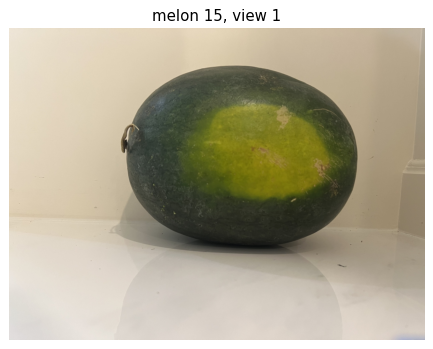

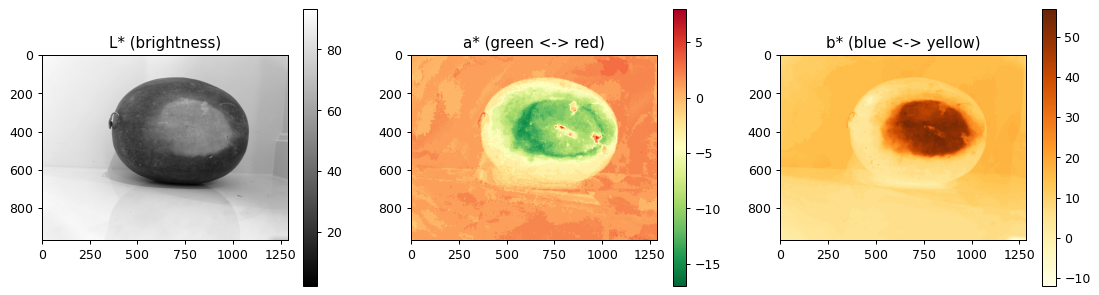

In [5]:
def read(path, scale=0.5):
    im = imread(path)
    return im, cv2.resize(im, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)

def lab_channels(im):
    lab = cv2.cvtColor(im, cv2.COLOR_BGR2LAB).astype(np.float32)
    return lab[..., 0] * 100 / 255, lab[..., 1] - 128, lab[..., 2] - 128

full, im = read(PREP_DIR / '15_v1.jpg')
L, a, b = lab_channels(im)
print('full size', full.shape, ' half size', im.shape)
show(im, 'melon 15, view 1')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for x, name, cmap in [(L, 'L* (brightness)', 'gray'), (a, 'a* (green <-> red)', 'RdYlGn_r'), (b, 'b* (blue <-> yellow)', 'YlOrBr')]:
    h = ax[['L','a','b'].index(name[0])].imshow(x, cmap=cmap); ax[['L','a','b'].index(name[0])].set_title(name); plt.colorbar(h, ax=ax[['L','a','b'].index(name[0])])
plt.show()

Look at the **b\*** panel: the yellow field spot lights up, which is why a simple threshold on b\* will find it.

## 4. Thresholds
Every number the detector uses. Change one and re-run the steps below to see how it behaves.

In [6]:
T = dict(
    web_a_min=-2.5, web_b_min=8,     # webbing: a* above, b* above (tan/brown)
    mask_a=-2.5,                     # melon skin: a* below (green) ...
    mask_dark=26,                    # ... or L* below (shaded side)
    spot_b=38,                       # field spot: b* above (yellow) ...
    spot_L=42,                       # ... and L* above (light)
    spot_min_frac=0.004,             # spot must cover 0.4% of the rind
    pale_chroma=22,                  # webbing/gloss candidates: low chroma ...
    pale_hue=108,                    # ... and less green than the rind
    gloss_L=46,                      # gloss: the brightest of those
    stripe_light_b=17,               # light stripe: b* above
    stripe_min_px=6,                 # ignore shorter runs
    bee_blackhat=22,                 # bee sting: this much darker than around it ...
    bee_L=26, bee_a=-4.5, bee_b=10,  # ... and brown/black, not dark green
    bee_area=(6, 500),               # size in full-resolution pixels
    side_min_ratio=1.07,             # axis ratio below this = end-on view
)

## 5. Find the melon (segmentation)
Goal: a mask that is 1 on the melon and 0 on the floor and wall.
1. Keep pixels that are green (`a < -2.5`) and not too bright, **or** very dark (the shaded side of dark melons).
2. `MORPH_OPEN` removes small specks. `connectedComponentsWithStats` finds separate blobs and we keep the biggest one.
3. `MORPH_CLOSE` fills holes (spots, stickers that were not green).
4. A melon has no dents, so the **convex hull** (a rubber band around the shape) gives a clean outline.

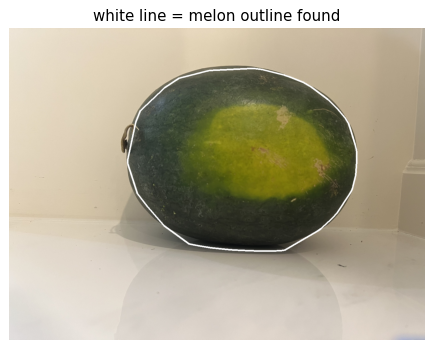

melon pixels: 319539


In [7]:
def segment(L, a, b):
    m = (((a < T['mask_a']) & (L < 75)) | (L < T['mask_dark'])).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((9, 9), np.uint8))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(m)
    k = 1 + np.argmax(st[1:, cv2.CC_STAT_AREA]); m = (lbl == k).astype(np.uint8)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, np.ones((25, 25), np.uint8))
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    hull = cv2.convexHull(max(cnts, key=cv2.contourArea))
    out = np.zeros_like(m); cv2.drawContours(out, [hull], -1, 1, -1)
    return out, hull

mask, hull = segment(L, a, b)
vis = im.copy(); cv2.drawContours(vis, [hull], -1, (255, 255, 255), 3)
show(vis, 'white line = melon outline found')
print('melon pixels:', int(mask.sum()))

## 6. Price sticker
Some melons carry a sticker whose colours would be mistaken for a field spot. Its rim is **orange** (a\* > 5), which a melon never is, so we start from orange pixels, grow outward over the sticker's yellow/blue/red print, fill the outline, and exclude it. Melon 13 view 3 has one.

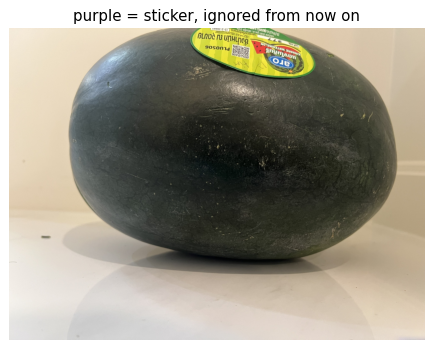

In [8]:
def find_sticker(L, a, b, mask):
    inside = mask > 0
    seed = ((a > 5) & (b > 20) & (L > 45) & inside).astype(np.uint8)
    seed = cv2.morphologyEx(seed, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    if seed.sum() < 300:
        return np.zeros_like(seed)
    print_ = (((b > 38) & (L > 45)) | ((b < -5) & (L > 50)) | (a > 5)) & inside
    grow = cv2.morphologyEx(print_.astype(np.uint8), cv2.MORPH_CLOSE, np.ones((21, 21), np.uint8))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(grow)
    out = np.zeros_like(seed)
    for i in np.unique(lbl[seed > 0]):
        if i == 0: continue
        pts = cv2.findNonZero((lbl == i).astype(np.uint8))
        cv2.drawContours(out, [cv2.convexHull(pts)], -1, 1, -1)
    return cv2.dilate(out, np.ones((9, 9), np.uint8))

f13, im13 = read(PREP_DIR / '13_v3.jpg'); L13, a13, b13 = lab_channels(im13)
m13, h13 = segment(L13, a13, b13); st13 = find_sticker(L13, a13, b13, m13)
v = im13.copy(); v[st13 > 0] = (255, 0, 255); show(cv2.addWeighted(v, .6, im13, .4, 0), 'purple = sticker, ignored from now on')

## 7. Rind area, view type and width-to-height ratio
* **Rind** = the mask shrunk a little (`erode`, so edge pixels that blend with the floor are dropped) minus the sticker. All percentages below are "% of rind pixels".
* `cv2.fitEllipse` fits an ellipse to the outline. **long axis ÷ short axis** is the width-to-height ratio you asked for (1.0 = round).
* If that ratio is under 1.07 the melon is being seen end-on (stem or blossom end), so it is flagged `end` and skipped for stripe width.

rind pixels: 301871
ellipse axes 713 x 575 px  ->  ratio 1.240   (view type: side)
bounding box ratio w/h = 1.254


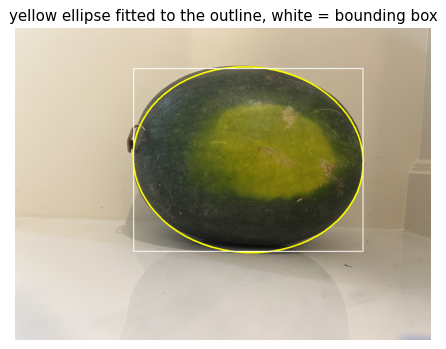

In [9]:
sticker = find_sticker(L, a, b, mask)
rind = cv2.erode(mask, np.ones((15, 15), np.uint8)); rind[sticker > 0] = 0
(cx, cy), (ea, eb), ang = cv2.fitEllipse(hull)
major, minor = max(ea, eb), min(ea, eb)
x, y, w, h = cv2.boundingRect(hull)
print('rind pixels:', int(rind.sum()))
print(f'ellipse axes {major:.0f} x {minor:.0f} px  ->  ratio {major/minor:.3f}   (view type: {"side" if major/minor >= T["side_min_ratio"] else "end"})')
print(f'bounding box ratio w/h = {w/h:.3f}')
vis = im.copy(); cv2.ellipse(vis, ((cx, cy), (ea, eb), ang), (0, 255, 255), 3); cv2.rectangle(vis, (x, y), (x+w, y+h), (255, 255, 255), 2)
show(vis, 'yellow ellipse fitted to the outline, white = bounding box')

## 8. Field spot
A field spot is a **light, strongly yellow** patch: `b* > 38` and `L* > 42`, inside the rind. Then:
* `MORPH_OPEN` removes isolated yellow pixels.
* Blobs smaller than 0.4% of the rind are dropped (so the spot is a patch, not noise).
* The spot's colour is the **average L\*, a\*, b\*** of its pixels. These are the three colour columns in the sheet.

spot area = 25.45% of rind
colour:  L* 50.2   a* -9.8   b* 48.8


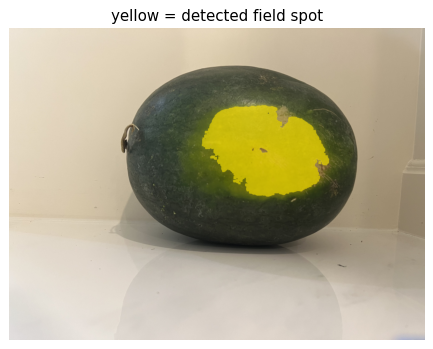

In [10]:
def find_spot(L, a, b, rind):
    rind_px = int(rind.sum())
    spot = ((b > T['spot_b']) & (L > T['spot_L']) & (rind > 0)).astype(np.uint8)
    spot = cv2.morphologyEx(spot, cv2.MORPH_OPEN, np.ones((7, 7), np.uint8))
    n, lbl, st, _ = cv2.connectedComponentsWithStats(spot)
    keep = np.zeros_like(spot)
    for i in range(1, n):
        if st[i, cv2.CC_STAT_AREA] >= T['spot_min_frac'] * rind_px: keep[lbl == i] = 1
    return keep

spot = find_spot(L, a, b, rind)
present = spot.sum() > 0
print('spot area = %.2f%% of rind' % (100 * spot.sum() / rind.sum()))
if present:
    print('colour:  L* %.1f   a* %.1f   b* %.1f' % (L[spot > 0].mean(), a[spot > 0].mean(), b[spot > 0].mean()))
v = im.copy(); v[spot > 0] = (0, 230, 255); show(cv2.addWeighted(v, .6, im, .4, 0), 'yellow = detected field spot')

**Try it:** change `spot_b` in the thresholds cell to 30 and re-run. The detected area grows, because paler yellow now counts.

## 9. Gloss and webbing
Both are "not the normal green rind", so we first find **pale pixels**: low colour intensity (chroma `C* = sqrt(a² + b²)`) and a hue angle that is less green than the stripes.
* **Gloss**: the *brightest* pale pixels (blurred L\* ≥ 46) are the specular highlights where light reflects off the shiny rind. `rind gloss` is the % of rind pixels in that set.
* **Webbing**: tan/brown corky scar tissue. Its colour has a\* near 0 or above (not green) and some yellow-brown (b\* from 8 up to the spot threshold), not too dark, and **not near a highlight** (glare also looks pale).

gloss 4.21%   webbing 6.33%


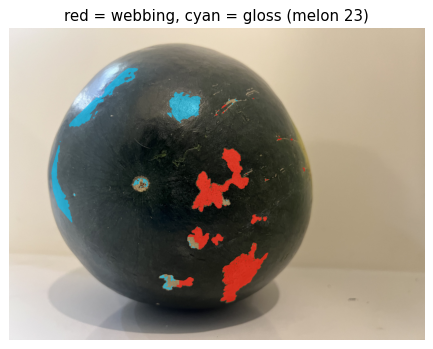

In [11]:
def gloss_webbing(L, a, b, rind, spot):
    C = np.hypot(a, b); hue = np.degrees(np.arctan2(b, a))
    pale = (C < T['pale_chroma']) & (hue < T['pale_hue']) & (rind > 0) & (spot == 0)
    Ls = cv2.GaussianBlur(L, (0, 0), 2)
    gloss = (pale & (Ls >= T['gloss_L'])).astype(np.uint8)
    gloss = cv2.morphologyEx(gloss, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    near_gloss = cv2.dilate(gloss, np.ones((25, 25), np.uint8))
    webbing = ((a > T['web_a_min']) & (b > T['web_b_min']) & (b < T['spot_b']) & (L >= 38)
               & (rind > 0) & (spot == 0) & (near_gloss == 0)).astype(np.uint8)
    webbing = cv2.morphologyEx(webbing, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    return gloss, webbing

fm, imm = read(PREP_DIR / '23_v4.jpg'); Lm, am, bm = lab_channels(imm)
mk, hl = segment(Lm, am, bm); stk = find_sticker(Lm, am, bm, mk)
rd = cv2.erode(mk, np.ones((15, 15), np.uint8)); rd[stk > 0] = 0
sp = find_spot(Lm, am, bm, rd); gl, wb = gloss_webbing(Lm, am, bm, rd, sp)
print('gloss %.2f%%   webbing %.2f%%' % (100*gl.sum()/rd.sum(), 100*wb.sum()/rd.sum()))
v = imm.copy(); v[wb > 0] = (0, 0, 255); v[gl > 0] = (255, 200, 0); show(cv2.addWeighted(v, .6, imm, .4, 0), 'red = webbing, cyan = gloss (melon 23)')

These are the least exact measures: gloss depends on where the light was, and webbing can pick up the odd scratch. Always glance at the overlay before trusting a number.

## 10. Stripe width (striped melons only)
Stripes run roughly horizontally in side views, so we walk **down vertical lines** through the middle of the melon and see how the colour changes: light-green stripe (b\* above 17 after blur) → dark stripe → light → …
* Each unbroken run of "dark" pixels is one dark stripe; its length in pixels is the stripe width.
* We skip the top and bottom 20% (stripes bunch together there), lines that cross the sticker or edge, and the first/last run of each line (cut off by the window).
* The reported number is `mean dark run / melon height`, so it does not depend on how big the melon looks in the photo.

dark stripe width / height = 0.169   light = 0.066   dark stripes per scan line = 2


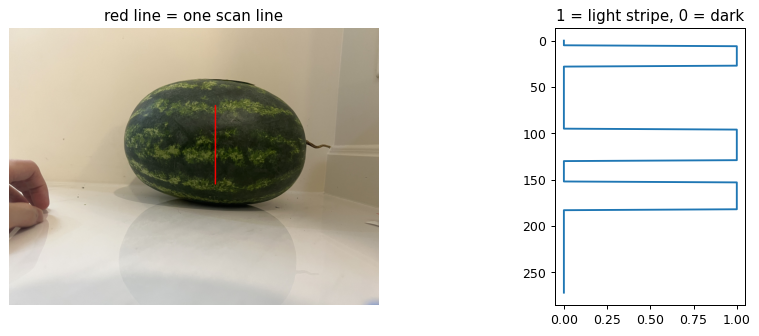

In [12]:
def stripe_width(L, a, b, rind, hull_box):
    x, y, w, h = hull_box
    bb = cv2.GaussianBlur(b, (0, 0), 3)
    light = (bb > T['stripe_light_b'])
    y0, y1 = int(y + 0.2 * h), int(y + 0.8 * h)
    dark_runs, light_runs, n_dark = [], [], []
    for cx in range(int(x + 0.25 * w), int(x + 0.75 * w), 4):
        col_ok = rind[y0:y1, cx] > 0
        if col_ok.mean() < 0.95: continue
        s = light[y0:y1, cx]
        edges = np.flatnonzero(np.diff(s.astype(np.int8))) + 1
        bounds = np.r_[0, edges, len(s)]
        runs = [(bounds[i], bounds[i + 1] - bounds[i], bool(s[bounds[i]])) for i in range(len(bounds) - 1)]
        runs = [r for r in runs if r[1] >= T['stripe_min_px']]
        inner = runs[1:-1]
        dark_runs += [r[1] for r in inner if not r[2]]
        light_runs += [r[1] for r in inner if r[2]]
        n_dark.append(sum(1 for r in runs if not r[2]))
    if not dark_runs: return np.nan, np.nan, np.nan
    return np.mean(dark_runs) / h, np.mean(light_runs) / h if light_runs else np.nan, float(np.median(n_dark))

fs, ims = read(PREP_DIR / '25_v3.jpg'); Ls_, as_, bs_ = lab_channels(ims)
ms, hs = segment(Ls_, as_, bs_); rs = cv2.erode(ms, np.ones((15, 15), np.uint8))
box = cv2.boundingRect(hs); sw = stripe_width(Ls_, as_, bs_, rs, box)
print('dark stripe width / height = %.3f   light = %.3f   dark stripes per scan line = %.0f' % sw)
xx, yy, ww, hh = box; cx0 = int(xx + 0.5*ww); y0, y1 = int(yy+.2*hh), int(yy+.8*hh)
lightmask = cv2.GaussianBlur(bs_, (0, 0), 3) > T['stripe_light_b']
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [3, 1]})
v = ims.copy(); cv2.line(v, (cx0, y0), (cx0, y1), (0, 0, 255), 3); ax[0].imshow(cv2.cvtColor(v, cv2.COLOR_BGR2RGB)); ax[0].axis('off'); ax[0].set_title('red line = one scan line')
ax[1].plot(lightmask[y0:y1, cx0].astype(int), range(y1-y0)); ax[1].invert_yaxis(); ax[1].set_title('1 = light stripe, 0 = dark')
plt.show()

## 11. Bee stings
A bee sting is a **small, dark, round, isolated** brown dot. This step runs on the **full-size** image because the dots are only a few pixels wide.
1. **Black-hat** (`MORPH_BLACKHAT`) highlights spots that are darker than their surroundings. This ignores the overall dark of the melon and finds local dark dots.
2. Keep pixels that are strongly dark-spot AND brown/black rather than dark green (`L`, `a`, `b` limits), away from the melon edge and the sticker.
3. Keep blobs of the right size, roughly round (not long scratches or hairs).
4. A real sting is **isolated**: dots with another candidate within 80 px are speckle texture, so they are not counted.

6 candidate dots -> 3 counted after the isolation rule
scanned 858,312 px  ->  density 3.50 per megapixel


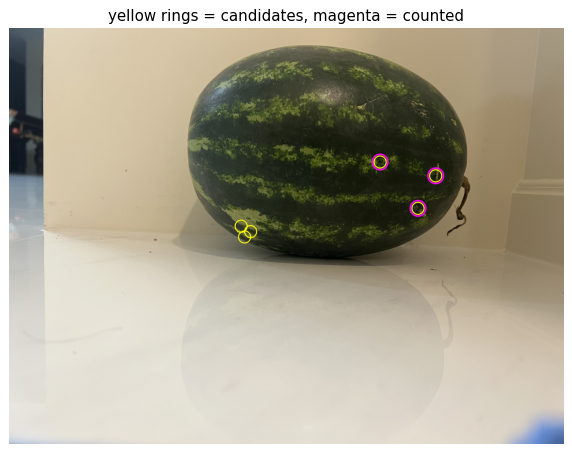

In [13]:
def bee_stings(im_full, rind_full, sticker_full):
    """Small dark isolated dots on the rind."""
    L, a, b = lab_channels(im_full)
    Lb = cv2.GaussianBlur(L, (0, 0), 1.2)
    bh = cv2.morphologyEx(Lb, cv2.MORPH_BLACKHAT,
                          cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (41, 41)))
    inner = cv2.erode(rind_full, np.ones((61, 61), np.uint8))
    searched_px = int(inner.sum())
    cand = ((bh > T['bee_blackhat']) & (Lb < T['bee_L']) & (a > T['bee_a'])
            & (b < T['bee_b']) & (inner > 0) & (sticker_full == 0)).astype(np.uint8)
    n, lbl, st, cen = cv2.connectedComponentsWithStats(cand)
    pts = []
    for i in range(1, n):
        area = st[i, cv2.CC_STAT_AREA]
        bw, bhh = st[i, cv2.CC_STAT_WIDTH], st[i, cv2.CC_STAT_HEIGHT]
        if not (T['bee_area'][0] <= area <= T['bee_area'][1]): continue
        if max(bw, bhh) / max(1, min(bw, bhh)) > 2.2: continue
        if area / (bw * bhh) < 0.45: continue
        pts.append((int(cen[i][0]), int(cen[i][1]), int(area)))
    iso = []
    for i, (x, y, ar) in enumerate(pts):
        if all(np.hypot(x - x2, y - y2) >= 80 for j, (x2, y2, _) in enumerate(pts) if j != i):
            iso.append((x, y, ar))
    return pts, iso, searched_px

fb, imb = read(PREP_DIR / '01_v1.jpg'); Lb_, ab_, bb_ = lab_channels(imb)
mb, hb = segment(Lb_, ab_, bb_); sb = find_sticker(Lb_, ab_, bb_, mb)
rb = cv2.erode(mb, np.ones((15, 15), np.uint8)); rb[sb > 0] = 0
up = lambda m: cv2.resize(m, (fb.shape[1], fb.shape[0]), interpolation=cv2.INTER_NEAREST)
cands, stings, scanned = bee_stings(fb, up(rb), up(sb))
print(len(cands), 'candidate dots ->', len(stings), 'counted after the isolation rule')
print(f'scanned {scanned:,} px  ->  density {1e6 * len(stings) / scanned:.2f} per megapixel')
v = fb.copy()
for (px, py, ar) in cands: cv2.circle(v, (px, py), 28, (0, 255, 255), 3)
for (px, py, ar) in stings: cv2.circle(v, (px, py), 36, (255, 0, 255), 5)
show(v, 'yellow rings = candidates, magenta = counted', size=8)

## 12. Everything in one function
`process()` runs steps 3-11 on a photo and returns one row of numbers, plus the layers for the overlay picture. `overlay()` paints what was found so you can check the numbers by eye.

{'file': '15_v1.jpg', 'view_type': 'side', 'rind_px': 301871, 'rind_b_med': 10.0, 'spot_area_pct': 25.445637374905175, 'spot_L': 50.162132263183594, 'spot_a': -9.78857707977295, 'spot_b': 48.759544372558594, 'webbing_pct': 0.5932997869951072, 'gloss_pct': 0.03180166362452836, 'dark_stripe_width_over_height': nan, 'dark_stripes_per_scanline': nan, 'axis_ratio': 1.2400101094922549, 'bee_sting_count': 0, 'bee_area_px': 1061684}


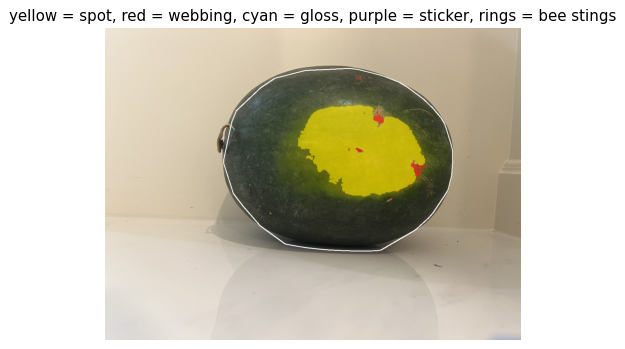

In [14]:
def process(path):
    full, im = read(path, 0.5)
    L, a, b = lab_channels(im)
    mask, hull = segment(L, a, b)
    sticker = find_sticker(L, a, b, mask)
    rind = cv2.erode(mask, np.ones((15, 15), np.uint8)); rind[sticker > 0] = 0
    rind_px = int(rind.sum())

    (cx, cy), (ea, eb), ang = cv2.fitEllipse(hull)
    major, minor = max(ea, eb), min(ea, eb)
    axis_ratio = major / minor
    x, y, w, h = cv2.boundingRect(hull)
    side_view = axis_ratio >= T['side_min_ratio']

    spot = find_spot(L, a, b, rind); spot_present = bool(spot.sum() > 0)
    gloss, webbing = gloss_webbing(L, a, b, rind, spot)

    plain = (rind > 0) & (spot == 0) & (webbing == 0) & (gloss == 0)
    rind_b_med = float(np.median(b[plain])) if plain.any() else np.nan

    sw = (np.nan, np.nan, np.nan)
    if side_view:
        p = rind.copy(); p[cv2.dilate(spot, np.ones((15, 15), np.uint8)) > 0] = 0
        sw = stripe_width(L, a, b, p, (x, y, w, h))

    up = lambda m: cv2.resize(m, (full.shape[1], full.shape[0]),
                              interpolation=cv2.INTER_NEAREST)
    _, iso, bee_area_px = bee_stings(full, up(rind), up(sticker))

    row = dict(file=Path(path).name, view_type='side' if side_view else 'end',
        rind_px=rind_px, rind_b_med=rind_b_med,
        spot_area_pct=100 * spot.sum() / rind_px,
        spot_L=float(L[spot > 0].mean()) if spot_present else np.nan,
        spot_a=float(a[spot > 0].mean()) if spot_present else np.nan,
        spot_b=float(b[spot > 0].mean()) if spot_present else np.nan,
        webbing_pct=100 * webbing.sum() / rind_px,
        gloss_pct=100 * gloss.sum() / rind_px,
        dark_stripe_width_over_height=sw[0], dark_stripes_per_scanline=sw[2],
        axis_ratio=axis_ratio,
        bee_sting_count=len(iso), bee_area_px=bee_area_px)
    return row, dict(im=im, hull=hull, spot=spot, webbing=webbing,
                     gloss=gloss, sticker=sticker, pts=iso)

def overlay(layers):
    im = layers['im'].copy(); ov = im.copy()
    ov[layers['spot'] > 0] = (0, 230, 255); ov[layers['webbing'] > 0] = (0, 0, 255)
    ov[layers['gloss'] > 0] = (255, 200, 0); ov[layers['sticker'] > 0] = (255, 0, 255)
    im = cv2.addWeighted(ov, 0.55, im, 0.45, 0); cv2.drawContours(im, [layers['hull']], -1, (255, 255, 255), 2)
    for (px, py, ar) in layers['pts']: cv2.circle(im, (px // 2, py // 2), 14, (255, 0, 255), 2)
    return im

row, layers = process(PREP_DIR / '15_v1.jpg'); print(row)
show(overlay(layers), 'yellow = spot, red = webbing, cyan = gloss, purple = sticker, rings = bee stings')

## 13. Run on all photos
Takes a few minutes (each photo is processed at full size for the bee-sting step), and prints progress as it goes. It reads `prepared/*_v1..6.jpg`, so the ID photos (`*_id.jpg`) are not used. The result is one row per photo.

If a photo makes a step throw (a blurred shot where no outline can be fitted, say), it is reported and skipped rather than stopping the run.

In [15]:
rows, ovs = [], {}
todo = sorted(PREP_DIR.glob('*_v[1-6].jpg'))
print(len(todo), 'view photos to process')
for i, f in enumerate(todo, 1):
    try:
        r, lay = process(f)
    except Exception as e:
        print(f'  [{i}/{len(todo)}] {f.name}: skipped ({type(e).__name__}: {e})')
        continue
    r['melon_id'] = int(f.name.split('_')[0]); rows.append(r)
    ovs[f.name] = overlay(lay)
    if i % 25 == 0 or i == len(todo): print(f'  {i}/{len(todo)} done')
per_photo = pd.DataFrame(rows)
print(len(per_photo), 'rows,', per_photo.melon_id.nunique(), 'melons')
per_photo.round(2).head(12)

149 view photos to process


  25/149 done


  50/149 done


  75/149 done


  100/149 done


  125/149 done


  149/149 done
149 rows, 25 melons


,file,view_type,rind_px,rind_b_med,spot_area_pct,spot_L,spot_a,spot_b,webbing_pct,gloss_pct,dark_stripe_width_over_height,dark_stripes_per_scanline,axis_ratio,bee_sting_count,bee_area_px,melon_id
0,01_v1.jpg,side,247162,10.0,0.00,NaN,NaN,NaN,0.10,0.66,0.13,4.0,1.25,3,858312,1
1,01_v2.jpg,side,210340,12.0,0.00,NaN,NaN,NaN,0.05,0.07,0.11,4.0,1.30,3,718964,1
2,01_v3.jpg,side,218450,14.0,0.00,NaN,NaN,NaN,0.15,0.18,0.09,3.0,1.29,1,749916,1
3,01_v4.jpg,side,213889,15.0,0.00,NaN,NaN,NaN,0.01,0.13,0.08,3.0,1.30,1,733392,1
4,01_v5.jpg,side,190562,9.0,0.00,NaN,NaN,NaN,0.34,0.66,0.15,2.0,1.08,2,645424,1
5,01_v6.jpg,end,219465,13.0,0.00,NaN,NaN,NaN,0.31,0.68,NaN,NaN,1.07,2,752516,1
6,02_v1.jpg,side,316892,18.0,0.00,NaN,NaN,NaN,0.33,0.45,0.07,3.0,1.28,0,1127736,2
7,02_v2.jpg,side,326545,19.0,2.14,54.08,-9.07,42.97,0.41,1.50,0.09,3.0,1.21,0,1173732,2
8,02_v3.jpg,side,300487,21.0,0.00,NaN,NaN,NaN,0.01,0.63,0.09,2.0,1.35,0,1055760,2
9,02_v4.jpg,side,332524,17.0,0.00,NaN,NaN,NaN,0.01,1.34,0.07,4.0,1.29,1,1195132,2


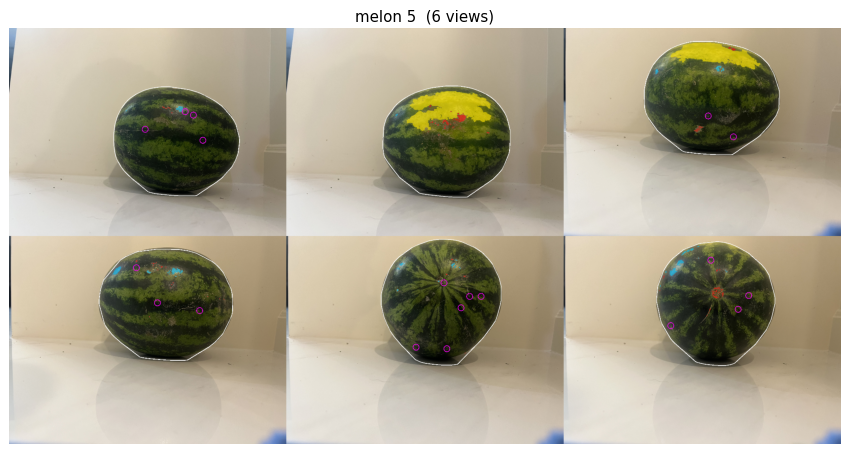

In [16]:
def melon_sheet(n, cols=3):
    tiles = [cv2.resize(ovs[k], (640, 480)) for k in (f'{n:02d}_v{i}.jpg' for i in range(1, 7)) if k in ovs]
    if not tiles:
        print(f'no overlays for melon {n} - available melons:',
              sorted({int(k.split("_")[0]) for k in ovs}))
        return
    blank = np.zeros_like(tiles[0])
    rows_ = [tiles[i:i + cols] for i in range(0, len(tiles), cols)]
    grid = np.vstack([np.hstack(r + [blank] * (cols - len(r))) for r in rows_])
    show(grid, f'melon {n}  ({len(tiles)} views)', size=12)

melon_sheet(5)

## 14. One value per melon
Per melon (6 photos):
* **field spot**: the biggest spot area seen in any photo (the underside photo shows it best). Colour = mean L\*a\*b\* of photos where a spot was found.
* **webbing, rind gloss, bee stings**: average over the photos.
* **stripe width, shape uniformity (width ÷ height)**: median over side views only.
* **Excluded photos**: three had failed outlines (04_v3 was blurry with a hand in frame; 23_v2 and 24_v2 were end-on shots where the outline was wrong). Edit `BAD` to change this.
* Stripe width is blanked for kinnaree melons, which are plain dark with no stripes.

In [17]:
BAD = {'04_v3.jpg', '23_v2.jpg', '24_v2.jpg'}
SHEET_CSV = """no,type,Brix top,Brix middle,Brix bottom,Name,Brix sum
1,sonya,6.2,7.8,6.0,Makro,6.666666667
2,sonya,5.6,8.9,8.0,Aro,7.5
3,sonya,8.0,6.8,6.4,Zhonya,7.066666667
4,sonya,7.9,9.6,8.0,freddy,8.5
5,sonya,6.9,7.2,5.4,Markiplier,6.5
6,sonya,9.1,10.6,10.8,IshowSpeed,10.166666667
7,sonya,6.2,8.0,6.0,Claude,6.733333333
8,sonya,7.8,11.0,8.6,king,9.133333333
9,sonya,8.2,10.1,9.2,luther,9.166666667
10,sonya,6.4,7.8,7.2,martin,7.133333333
11,kinnaree,7.0,10.8,10.8,Kayn,9.533333333
12,kinnaree,6.9,11.2,7.8,Jayce,8.633333333
13,kinnaree,7.2,11.0,8.0,Tim,8.733333333
14,kinnaree,6.0,8.0,6.9,michael,6.966666667
15,kinnaree,6.0,9.0,7.0,Andre,7.333333333
16,kinnaree,6.4,8.5,7.0,Jyn,7.3
17,kinnaree,8.0,10.0,9.2,Pyke,9.066666667
18,kinnaree,6.0,8.4,5.4,Andy,6.6
19,kinnaree,8.0,11.0,8.2,Surapraween,9.066666667
20,kinnaree,8.4,11.3,9.0,Sasha,9.566666667
21,kinnaree,9.2,7.9,7.2,banner,8.1
22,kinnaree,8.9,10.0,8.2,Joseph,9.033333333
23,kinnaree,9.2,10.1,7.7,Tasque,9.0
24,kinnaree,8.4,9.8,8.6,Mike,8.933333333
25,sonya,3.8,7.0,6.0,Fridge,5.6"""
sheet = pd.read_csv(io.StringIO(SHEET_CSV))

d    = per_photo[~per_photo.file.isin(BAD)]
side = d[d.view_type == 'side']

out = []
for m, g in d.groupby('melon_id'):
    sp = g[g.spot_area_pct >= 0.4]
    gs = side[side.melon_id == m]
    out.append({
        'no': m,
        'n_views': len(g),
        'rind_px': g.rind_px.median(),
        'field_spot_area_pct': g.spot_area_pct.max(),
        'webbing':    g.webbing_pct.mean(),
        'rind_gloss': g.gloss_pct.mean(),
        'shape_uniformity': g.axis_ratio.max(),
        'bee_sting_density': 1e6 * g.bee_sting_count.sum() / g.bee_area_px.sum(),
        'spot_present': int(len(sp) > 0),
        'field_spot_b': sp.spot_b.mean() if len(sp) else np.nan,
        'field_spot_l': sp.spot_L.mean() if len(sp) else np.nan,
        'field_spot_a': sp.spot_a.mean() if len(sp) else np.nan,
        'rind_b': g.rind_b_med.median(),
        'stripe_width_sonya_only': gs.dark_stripe_width_over_height.median(),
    })

feat = pd.DataFrame(out).merge(sheet, on='no')
feat.loc[feat.type != 'sonya', 'stripe_width_sonya_only'] = np.nan

assert len(feat) == feat.no.nunique() == per_photo.melon_id.nunique(), \
    'one row per melon broken - check the melon_id parsing in step 13'

CSV_OUT = Path('watermelon_features.csv')
feat.to_csv(CSV_OUT, index=False)
print('wrote', CSV_OUT.resolve(), f'({len(feat)} melons)')
feat

wrote D:\Watermelon\watermelon_features.csv (25 melons)


,no,n_views,rind_px,field_spot_area_pct,webbing,rind_gloss,shape_uniformity,bee_sting_density,spot_present,field_spot_b,field_spot_l,field_spot_a,rind_b,stripe_width_sonya_only,type,Brix top,Brix middle,Brix bottom,Name,Brix sum
0,1,6,216169.5,0.000000,0.160501,0.395869,1.299186,2.691474,0,NaN,NaN,NaN,12.5,0.113253,sonya,6.2,7.8,6.0,Makro,6.666667
1,2,6,308689.5,2.143656,0.291723,0.753265,1.351188,0.162940,1,43.673004,51.458763,-7.340630,18.5,0.068784,sonya,5.6,8.9,8.0,Aro,7.500000
2,3,6,264945.0,18.103415,0.516497,0.835412,1.264280,1.217678,1,45.284081,51.962543,-10.847005,14.0,0.117247,sonya,8.0,6.8,6.4,Zhonya,7.066667
3,4,5,222931.0,0.000000,0.226696,0.448445,1.335540,0.243432,0,NaN,NaN,NaN,13.0,0.119103,sonya,7.9,9.6,8.0,freddy,8.500000
4,5,6,232383.0,17.812140,0.282412,0.416182,1.181577,3.936580,1,49.314081,57.210821,-11.513911,14.5,0.093957,sonya,6.9,7.2,5.4,Markiplier,6.500000
5,6,5,357348.0,0.573111,0.243008,1.607665,1.485343,2.774342,1,41.809940,66.313812,-12.124795,9.0,0.150704,sonya,9.1,10.6,10.8,IshowSpeed,10.166667
6,7,6,300030.0,15.632135,1.505229,1.236248,1.317662,0.781121,1,46.815809,51.417532,-5.210842,8.0,0.115570,sonya,6.2,8.0,6.0,Claude,6.733333
7,8,6,243669.5,3.877841,0.181271,0.546747,1.232671,4.576062,1,46.004429,52.291607,-13.435369,10.0,0.121611,sonya,7.8,11.0,8.6,king,9.133333
8,9,6,380999.0,16.130263,0.747140,2.238279,1.322294,1.203320,1,48.583393,61.674744,-3.933852,11.0,0.133689,sonya,8.2,10.1,9.2,luther,9.166667
9,10,6,277101.0,16.001105,0.357764,0.701612,1.252143,0.791212,1,46.630604,55.636921,-11.150400,12.0,0.117932,sonya,6.4,7.8,7.2,martin,7.133333


## 15. Do the features line up with sweetness?
A first look: how strongly does each feature move with **Brix sum** (the average of the three refractometer readings)? Correlation runs from −1 to +1; near 0 means no linear relationship. With only 25 melons, treat anything under about ±0.4 as noise.

In [18]:
PHOTO_CUES = ['field_spot_area_pct', 'webbing', 'rind_gloss',
              'shape_uniformity', 'bee_sting_density']

print('Spearman rho with Brix (photo cues; knock features are step 21)')
print('  folk direction: + for spot area, webbing, bee stings; - for gloss, shape')
for c in PHOTO_CUES + ['spot_present', 'rind_b']:
    rho = feat[c].corr(feat['Brix sum'], method='spearman')
    print(f'  {c:22s} {rho:+.3f}')

print('\n--- is rind_px melon size, or camera distance? ---')
w = per_photo[~per_photo.file.isin(BAD)].groupby('melon_id').rind_px.agg(['mean', 'std'])
within  = (w['std'] / w['mean']).mean()
between = w['mean'].std() / w['mean'].mean()
print(f'within-melon CV {within:.3f}   between-melon CV {between:.3f}   '
      f'ratio {between / within:.2f}')
print('  ratio > ~1.5 means it carries real size signal rather than shooting noise.')
print('  Excluded from training regardless (cell 51) - this is evidence, not a feature.')

print('\n--- missingness in the cue columns ---')
na = feat[PHOTO_CUES].isna().sum()
print('  ' + (na[na > 0].to_string() if (na > 0).any() else 'none - trainable'))
print(f"  melons with no detected field spot: {int((feat.spot_present == 0).sum())} of {len(feat)}")
print(f'  views per melon: min {feat.n_views.min()}, max {feat.n_views.max()}')

print('\n--- ranges ---')
print(feat[PHOTO_CUES + ['rind_px', 'field_spot_b', 'rind_b']]
      .describe().loc[['min', '50%', 'max']].round(3).to_string())

Spearman rho with Brix (photo cues; knock features are step 21)
  folk direction: + for spot area, webbing, bee stings; - for gloss, shape


  field_spot_area_pct    -0.206
  webbing                +0.269
  rind_gloss             +0.544
  shape_uniformity       +0.076
  bee_sting_density      -0.083
  spot_present           +0.039
  rind_b                 -0.251

--- is rind_px melon size, or camera distance? ---
within-melon CV 0.134   between-melon CV 0.239   ratio 1.78
  ratio > ~1.5 means it carries real size signal rather than shooting noise.
  Excluded from training regardless (cell 51) - this is evidence, not a feature.

--- missingness in the cue columns ---
  none - trainable
  melons with no detected field spot: 6 of 25
  views per melon: min 5, max 6

--- ranges ---
     field_spot_area_pct  webbing  rind_gloss  shape_uniformity  bee_sting_density   rind_px  field_spot_b  rind_b
min                0.000    0.108       0.016             1.155              0.163  194146.0        41.569     2.0
50%                2.165    0.358       0.952             1.272              1.591  300030.0        46.004     7.5
max     

---
# Part 2: knock sounds
## 16. Load the recordings
Put the knock recordings in `audio/` (subfolders are fine). The melon number is read from the filename: the **first group of one or two digits** in the name, so `01.wav`, `05_knock.m4a`, `melon_13.wav` and `knock-7-b.wav` all work. Several recordings of the same melon are averaged together.

The recordings in `audio/` are iPhone Voice Memos (`New Recording 35.m4a` …), whose numbers are the memo counter and not melon numbers, so `AUDIO_ID_OVERRIDE` in step 19 is already filled in for them: recording 35 is melon 1, 36 is melon 2, through to 59 for melon 25. Any file the override does not cover falls back to the digits in its name, and step 19 warns when that happens. The full mapping is printed for you to check before anything is computed.

Two things about loading:
* Everything is resampled to **22 050 Hz** mono, so recordings made on different devices are comparable.
* `librosa.load` uses libsndfile, which handles WAV/FLAC/OGG/MP3 but **not AAC** — and iPhone Voice Memos records `.m4a`. So `load_audio` falls back to PyAV, which bundles its own ffmpeg. I checked that an AAC copy of a WAV gives an identical `dominant_freq` and decay through this path; only the high-frequency spectral numbers shift slightly, which is lossy encoding, not a decode fault. **If you have the choice, record or export WAV.**

Steps 16–21 are skipped cleanly if `audio/` is empty, so the photo steps above still run.

In [19]:
import librosa, librosa.display

SR_TARGET = 22050
HOP       = 512
AUDIO_EXT = ['.wav', '.flac', '.ogg', '.mp3', '.m4a', '.aac', '.aif', '.aiff', '.caf', '.wma']

def _load_via_av(path, target_sr):
    """Decode what libsndfile cannot (.m4a/.aac/.wma) using PyAV's bundled ffmpeg."""
    try:
        import av
    except ImportError as e:
        raise RuntimeError(
            f'{Path(path).name}: libsndfile cannot read this format, and PyAV is not '
            f'installed.\nFix: pip install av   - or convert the recordings to .wav'
        ) from e
    with av.open(str(path)) as container:
        stream = container.streams.audio[0]
        rs = av.AudioResampler(format='flt', layout='mono', rate=target_sr)
        chunks = []
        for frame in container.decode(stream):
            chunks.extend(f.to_ndarray() for f in rs.resample(frame))
        chunks.extend(f.to_ndarray() for f in rs.resample(None))
    if not chunks:
        raise RuntimeError(f'{Path(path).name}: decoded to zero samples')
    return np.concatenate(chunks, axis=1).reshape(-1).astype(np.float32), target_sr

def load_audio(path, target_sr=SR_TARGET):
    """librosa.load, falling back to PyAV for formats libsndfile cannot open."""
    try:
        return librosa.load(str(path), sr=target_sr, mono=True)
    except Exception:
        return _load_via_av(path, target_sr)

audio_files = sorted(p for p in AUDIO_DIR.rglob('*')
                     if p.is_file() and p.suffix.lower() in AUDIO_EXT) \
              if AUDIO_DIR.is_dir() else []
HAVE_AUDIO = bool(audio_files)

print('audio folder:', AUDIO_DIR.resolve())
print('recordings  :', len(audio_files))
if HAVE_AUDIO:
    print('extensions  :', dict(Counter(p.suffix.lower() for p in audio_files)))
    print('first few   :', [p.name for p in audio_files[:6]])
else:
    print(f'\nNo audio found. Put the knock recordings in {AUDIO_DIR.resolve()}')
    print('Steps 16-21 will report "no audio" and do nothing; steps 1-15 are unaffected.')

audio folder: D:\Watermelon\audio
recordings  : 25
extensions  : {'.m4a': 25}
first few   : ['New Recording 35.m4a', 'New Recording 36.m4a', 'New Recording 37.m4a', 'New Recording 38.m4a', 'New Recording 39.m4a', 'New Recording 40.m4a']


## 17. Cut each recording into individual taps
A recording usually holds several taps with silence between them. Averaging features over the **whole file** would mostly measure the silence, so we find each tap and measure it on its own.

`librosa.onset.onset_detect` finds the attacks. Two corrections on top of it, both of which I confirmed matter on test recordings:

1. **Drop weak onsets.** The detector also fires part-way down a tap's decay. A window starting mid-ring has no attack, and its pitch reading is badly wrong — on my test set two such clips pushed `dominant_freq` out by up to 205 Hz and dragged the correlation with sweetness from −0.93 down to −0.35. So an onset is kept only if the signal reaches a quarter of the clip's peak within `probe_s` of it.
2. **Probe over 120 ms, not 30 ms.** `onset_detect(backtrack=True)` reports the quiet local minimum *before* the attack, sometimes 0.1 s before it. A short probe therefore measures silence and throws away real taps — that bug cost 19 of 25 taps before I caught it.

Each window then runs to `win` seconds **or the next tap, whichever comes first**, so the ring-out is captured as fully as the recording allows. Over `probe_s` 0.12–0.18, `min_gap` 0.15–0.25 and `rel_strength` 0.15–0.35 the result was identical on my test set, so these are a plateau rather than knife-edge values.

C:\Users\napat\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\napat\AppData\Local\Temp\ipykernel_35600\1626345445.py:32: UserWarning: PySoundFile failed. Trying audioread instead.
  return librosa.load(str(path), sr=target_sr, mono=True)
C:\Users\napat\AppData\Local\Programs\Python\Python311\Lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


New Recording 35.m4a: 2.90 s, 3 taps found
tap lengths (s): [0.5, 0.5, 0.486]


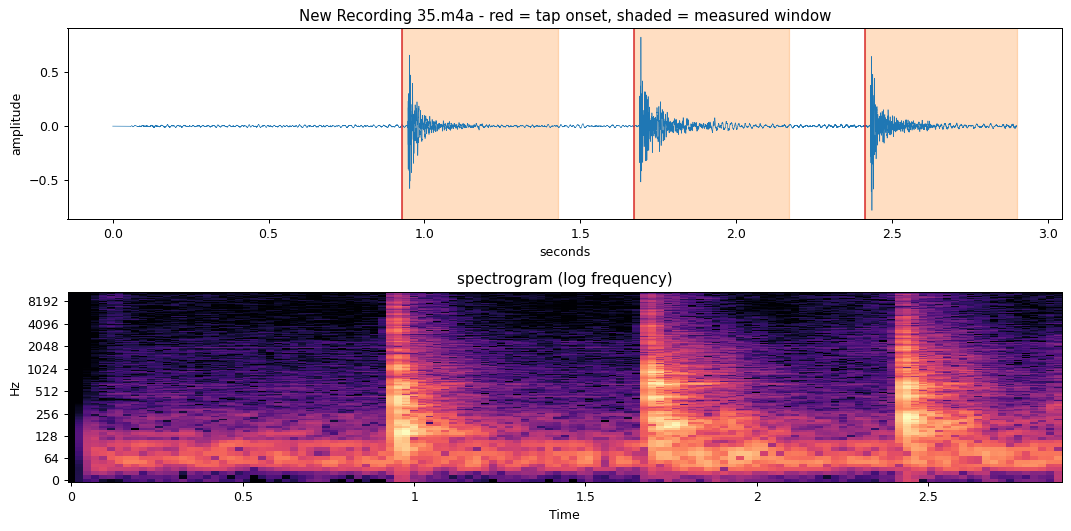

In [20]:
def knock_spans(y, sr, win=0.50, min_gap=0.15, top_db=30, rel_strength=0.25,
                probe_s=0.12):
    """Return [(start, end), ...] sample ranges, one per tap (see the notes above)."""
    if y.size == 0:
        return []
    env = np.abs(y)
    gpeak = float(env.max())
    n, floor, gap = int(win * sr), int(0.05 * sr), int(min_gap * sr)
    probe = max(int(probe_s * sr), 1)

    def attack(s):
        return float(env[s:s + probe].max()) if env[s:s + probe].size else 0.0

    cand = [int(s) for s in
            librosa.onset.onset_detect(y=y, sr=sr, units='samples', backtrack=True)]
    cand = [s for s in cand if y.size - s >= floor]
    if gpeak > 0:
        cand = [s for s in cand if attack(s) >= rel_strength * gpeak]

    keep, group = [], []
    for s in cand:
        if group and s - group[0] >= gap:
            keep.append(max(group, key=attack)); group = []
        group.append(s)
    if group:
        keep.append(max(group, key=attack))

    spans = []
    for i, s in enumerate(keep):
        end = min(s + n, keep[i + 1] if i + 1 < len(keep) else y.size)
        if end - s >= floor:
            spans.append((s, end))
    if not spans:
        trimmed, idx = librosa.effects.trim(y, top_db=top_db)
        spans = [(int(idx[0]), int(idx[1]))] if trimmed.size >= floor else [(0, y.size)]
    return spans

def knock_windows(y, sr, **kw):
    """The audio of each tap."""
    return [y[a:b] for a, b in knock_spans(y, sr, **kw)]

if not HAVE_AUDIO:
    print('no audio - skipping')
else:
    demo_path = audio_files[0]
    y_demo, sr_demo = load_audio(demo_path)
    spans_demo = knock_spans(y_demo, sr_demo)
    print(f'{demo_path.name}: {y_demo.size / sr_demo:.2f} s, {len(spans_demo)} taps found')
    print('tap lengths (s):', [round((b - a) / sr_demo, 3) for a, b in spans_demo])

    fig, ax = plt.subplots(2, 1, figsize=(12, 6))
    ax[0].plot(np.arange(y_demo.size) / sr_demo, y_demo, lw=0.5)
    for a, b in spans_demo:
        ax[0].axvspan(a / sr_demo, b / sr_demo, color='tab:orange', alpha=0.25)
        ax[0].axvline(a / sr_demo, color='tab:red', lw=1.2)
    ax[0].set_title(f'{demo_path.name} - red = tap onset, shaded = measured window')
    ax[0].set_xlabel('seconds'); ax[0].set_ylabel('amplitude')

    S = librosa.amplitude_to_db(np.abs(librosa.stft(y_demo, hop_length=HOP)), ref=np.max)
    librosa.display.specshow(S, sr=sr_demo, hop_length=HOP, x_axis='time', y_axis='log', ax=ax[1])
    ax[1].set_title('spectrogram (log frequency)')
    plt.tight_layout(); plt.show()

## 18. Features from one tap
`features_for_tap` takes **one isolated tap** and produces the three features that have a mechanism behind them:

| column | what it is | why it should track ripeness |
| --- | --- | --- |
| `dominant_freq` | strongest FFT bin between 50–2000 Hz | ripening breaks down pectin, the flesh softens, stiffness drops, so the resonant frequency falls |
| `mean_pitch` | magnitude-weighted `piptrack` estimate | a second estimator of that same resonant frequency |
| `decay_20db_s` | seconds to fall 20 dB from the peak | softer, more fluid-filled tissue dissipates energy faster, so the ring dies sooner |

`duration_s` comes along as a **diagnostic, not a feature**: if `decay_20db_s` equals it, the ring was cut off by the window and the true decay is longer.

**It must be given a tap, not a recording.** Frequency is measured on the first 0.25 s, so handed a whole file it measures the silence before the first tap — on the test recordings that reads 1888 Hz instead of 204 Hz. The cell below prints both numbers so the trap is visible. Step 19's `features_for_file` is the entry point for a recording; it splits into taps first, and `extract_and_average_features` is kept there as an alias to the sketch's name.

**`mean_pitch` and `dominant_freq` measure the same physical quantity**, so this is two independent ideas in three columns, not three. Step 19 prints their agreement; on the test recordings it is +0.998. If they ever disagree sharply, one has misfired and the recording is worth listening to.

Two deliberate differences from the sketch:

* **Pitch is magnitude-weighted.** The sketch takes `np.mean(pitches[pitches > 0])` over the whole `piptrack` matrix, which averages *every* spectral peak in every frame — harmonics and noise-floor peaks included. This version takes the strongest bin per frame and weights by magnitude, so the number tracks the actual ringing tone.
* **Frequency and decay are measured on different spans.** Frequency uses the first `tone_win` (0.25 s), where the ring dominates; decay uses the whole window. Measuring both on one span cost real signal in testing: a long span dragged the frequency correlation from −0.93 to −0.35, and a short span truncated the ring so the decay correlation collapsed from −0.89 to −0.04.

**What was dropped and why:** the MFCCs with their deltas and delta-deltas (39 columns) and the other spectral summaries (centroid, bandwidth, rolloff, flatness, zero-crossing rate, RMS). They are standard audio-classification features, but none of them has a stated reason to relate to sugar content, and ~50 features against 25 melons guarantees that the best of them looks convincing by luck. The reason to revisit that choice is **more melons**, not better statistics on these 25.

In [21]:
def features_for_tap(y, sr, tone_win=0.25):
    """The three ripeness features for ONE isolated tap."""
    y = np.asarray(y, dtype=np.float32)

    peak = float(np.max(np.abs(y))) if y.size else 0.0
    if peak > 0:
        y = y / peak

    n_tone = int(tone_win * sr)
    core = y[:n_tone] if y.size > n_tone else y

    pitches, magnitudes = librosa.piptrack(y=core, sr=sr, hop_length=HOP)
    frames = np.arange(pitches.shape[1])
    strongest = magnitudes.argmax(axis=0)
    f_hz, f_mag = pitches[strongest, frames], magnitudes[strongest, frames]
    voiced = f_hz > 0
    mean_pitch = float(np.average(f_hz[voiced], weights=f_mag[voiced])) if voiced.any() else 0.0

    window = np.hanning(core.size) if core.size > 1 else np.ones(1)
    spectrum = np.abs(np.fft.rfft(core * window))
    freqs = np.fft.rfftfreq(core.size, 1 / sr)
    band = (freqs >= 50) & (freqs <= 2000)
    dominant = float(freqs[band][spectrum[band].argmax()]) if band.any() else 0.0

    rms = librosa.feature.rms(y=y, hop_length=HOP)[0]
    pk = int(rms.argmax())
    tail = rms[pk:]
    below = np.flatnonzero(tail <= rms[pk] * 10 ** (-20 / 20))
    decay_s = float((below[0] if below.size else tail.size) * HOP / sr)

    return {
        'mean_pitch': mean_pitch,
        'dominant_freq': dominant,
        'decay_20db_s': decay_s,
        'duration_s': float(y.size / sr),
    }

if not HAVE_AUDIO:
    print('no audio - skipping')
else:
    a, b = spans_demo[0]
    f_one = features_for_tap(y_demo[a:b], sr_demo)
    print(f'first tap of {demo_path.name}:\n')
    for k, v in f_one.items():
        tag = '   <- diagnostic' if k == 'duration_s' else ''
        print(f'  {k:16s} {v:10.3f}{tag}')
    if f_one['decay_20db_s'] >= f_one['duration_s'] - 1e-9:
        print('\n  note: decay hit the window length, so the true ring is longer')

    whole = features_for_tap(y_demo, sr_demo)
    print(f'\nfor contrast, the same call on the whole recording:')
    print(f'  dominant_freq {whole["dominant_freq"]:8.1f} Hz  '
          f'(vs {f_one["dominant_freq"]:.1f} Hz for the tap)')
    print('  -> that is why recordings go through features_for_file, never directly here')

first tap of New Recording 35.m4a:

  mean_pitch          171.305
  dominant_freq       164.015
  decay_20db_s          0.186
  duration_s            0.500   <- diagnostic

for contrast, the same call on the whole recording:
  dominant_freq     60.0 Hz  (vs 164.0 Hz for the tap)
  -> that is why recordings go through features_for_file, never directly here


## 19. Run on every recording
Two levels of averaging, same idea as the photos:
* **per recording** — features averaged over the taps in that file, plus `n_knocks`.
* **per melon** — averaged over all recordings of that melon, plus `n_clips`.

**Check the melon numbers it prints.** The number comes from the filename, and if your names don't fit the pattern the mapping will be wrong in a way no error will catch. Put corrections in `AUDIO_ID_OVERRIDE` — keys are filenames without extension:

```python
AUDIO_ID_OVERRIDE = {'recording_001': 1, 'voice memo 3': 7}
```

A file whose number can't be read, or that fails to load, is reported and skipped rather than stopping the run.

In [22]:
import re

# voice-memo numbers are the phone's counter: recording 34 + n is melon n
AUDIO_ID_OVERRIDE = {f'New Recording {34 + n}': n for n in range(1, 26)}
_ID_RE = re.compile(r'(\d{1,2})')

def melon_id_from_name(name):
    """First group of 1-2 digits in the filename, unless overridden."""
    stem = Path(name).stem
    if stem in AUDIO_ID_OVERRIDE:
        return AUDIO_ID_OVERRIDE[stem]
    m = _ID_RE.search(stem)
    return int(m.group(1)) if m else None

def features_for_file(path, per_knock=True):
    """Load one recording, split it into taps, average the features over them."""
    y, sr = load_audio(path)
    segs = knock_windows(y, sr) if per_knock else [y]
    if not segs:
        return None
    rows = [features_for_tap(s, sr) for s in segs]
    out = {k: float(np.mean([r[k] for r in rows])) for k in rows[0]}
    out['n_knocks'] = len(segs)
    out['clip_duration_s'] = float(y.size / sr)
    return out

extract_and_average_features = features_for_file

AUDIO_SUMMARY_COLS = ['no', 'n_clips', 'n_knocks',
                      'dominant_freq', 'mean_pitch', 'decay_20db_s', 'duration_s']
per_clip_audio = audio_melon = pd.DataFrame()

if not HAVE_AUDIO:
    print('no audio - skipping')
else:
    uncovered = [p.name for p in audio_files if p.stem not in AUDIO_ID_OVERRIDE]
    if AUDIO_ID_OVERRIDE and uncovered:
        print(f'WARNING: {len(uncovered)} of {len(audio_files)} files are not in '
              f'AUDIO_ID_OVERRIDE, so their melon number is guessed from the digits '
              f'in the filename:')
        for n in uncovered[:8]:
            print(f'  {n}  -> melon {melon_id_from_name(n)}')
        print('  add them to AUDIO_ID_OVERRIDE if that is wrong\n')

    rows, unmapped, failed = [], [], []
    for i, p in enumerate(audio_files, 1):
        mid = melon_id_from_name(p.name)
        if mid is None:
            unmapped.append(p.name); continue
        try:
            f = features_for_file(p)
        except Exception as e:
            failed.append(f'{p.name}: {type(e).__name__}: {e}'); continue
        if f is None:
            failed.append(f'{p.name}: no usable audio'); continue
        f['no'] = mid; f['file'] = p.name
        rows.append(f)
        if i % 10 == 0 or i == len(audio_files):
            print(f'  {i}/{len(audio_files)} processed')

    for name in unmapped:
        print('  no melon number in filename, skipped:', name)
    for msg in failed:
        print('  failed:', msg)

    per_clip_audio = pd.DataFrame(rows)
    if per_clip_audio.empty:
        print('\nno usable recordings')
    else:
        numeric = [c for c in per_clip_audio.columns if c != 'file']
        audio_melon = per_clip_audio[numeric].groupby('no', as_index=False).mean()
        audio_melon['n_clips'] = per_clip_audio.groupby('no').size().values
        print(f'\n{len(per_clip_audio)} recordings -> {len(audio_melon)} melons')

        agree = per_clip_audio['dominant_freq'].corr(per_clip_audio['mean_pitch'])
        print(f'dominant_freq vs mean_pitch across recordings: r = {agree:+.3f} '
              f'(they measure the same quantity, so this should be near +1)')
        odd = per_clip_audio[(per_clip_audio['dominant_freq'] - per_clip_audio['mean_pitch']).abs() > 50]
        if not odd.empty:
            print('recordings where the two disagree by >50 Hz - worth listening to:')
            print('  ' + ', '.join(odd['file']))

        cut = per_clip_audio['decay_20db_s'] >= per_clip_audio['duration_s'] - 1e-9
        if cut.any():
            print(f'\n{int(cut.sum())} of {len(per_clip_audio)} recordings had the ring cut '
                  f'off by the window, so their decay is a lower bound')

        print('\nfilename -> melon number (check this):')
        for _, r in per_clip_audio[['file', 'no', 'n_knocks']].iterrows():
            print(f'  {r.file:34s} -> melon {int(r.no):2d}   ({int(r.n_knocks)} taps)')

audio_melon[AUDIO_SUMMARY_COLS].round(2) if not audio_melon.empty else audio_melon

C:\Users\napat\AppData\Local\Temp\ipykernel_35600\1626345445.py:32: UserWarning: PySoundFile failed. Trying audioread instead.
  return librosa.load(str(path), sr=target_sr, mono=True)
C:\Users\napat\AppData\Local\Programs\Python\Python311\Lib\site-packages\librosa\core\audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


  10/25 processed


  20/25 processed
  25/25 processed

25 recordings -> 25 melons
dominant_freq vs mean_pitch across recordings: r = +0.825 (they measure the same quantity, so this should be near +1)
recordings where the two disagree by >50 Hz - worth listening to:
  New Recording 35.m4a, New Recording 38.m4a, New Recording 39.m4a, New Recording 48.m4a, New Recording 53.m4a, New Recording 56.m4a, New Recording 57.m4a

filename -> melon number (check this):
  New Recording 35.m4a               -> melon  1   (3 taps)
  New Recording 36.m4a               -> melon  2   (3 taps)
  New Recording 37.m4a               -> melon  3   (3 taps)
  New Recording 38.m4a               -> melon  4   (3 taps)
  New Recording 39.m4a               -> melon  5   (3 taps)
  New Recording 40.m4a               -> melon  6   (3 taps)
  New Recording 41.m4a               -> melon  7   (3 taps)
  New Recording 42.m4a               -> melon  8   (3 taps)
  New Recording 43.m4a               -> melon  9   (3 taps)
  New Recording 4

,no,n_clips,n_knocks,dominant_freq,mean_pitch,decay_20db_s,duration_s
0,1,1,3.0,181.35,264.89,0.26,0.50
1,2,1,3.0,180.02,225.00,0.15,0.50
2,3,1,3.0,177.35,215.28,0.14,0.50
3,4,1,3.0,244.02,309.64,0.18,0.50
4,5,1,3.0,174.68,289.79,0.15,0.50
5,6,1,3.0,205.35,227.68,0.13,0.49
6,7,1,3.0,197.35,213.45,0.15,0.50
7,8,1,3.0,186.68,198.43,0.13,0.50
8,9,1,3.0,268.02,305.72,0.13,0.49
9,10,1,3.0,384.03,374.49,0.12,0.47


## 20. Merge the audio into the feature table
This joins the photo features from step 14 and the audio features from step 19 onto the melon number, and writes the complete table.

The join is **anchored on `sheet`** — the list of melons you measured Brix for — rather than on the photo table. Joining audio onto the photo table would quietly drop recordings of any melon whose photos failed segmentation; anchoring on the sheet means all 25 melons appear, with empty cells wherever an input is missing, and the cell prints which melons lack photos and which lack recordings.

I used a dataframe join rather than the sketch's `add_audio_features_to_table`, which reads the whole table off disk, edits one row and writes it back once per file. That works, but with one file per melon it rewrites the table 25 times and relies on the melon number matching whatever is already on disk. A `merge` is one operation and keeps the photo and audio paths independent. The sketch's row-at-a-time version is the right shape if you later want to append recordings without re-running the notebook.

The CSV written here supersedes the photo-only one from step 14 — same filename, now with the audio columns.

In [23]:
photo_only = ['no'] + [c for c in feat.columns if c not in sheet.columns]
feat_all = sheet.merge(feat[photo_only], on='no', how='left')

if audio_melon.empty:
    print('no audio features - feat_all holds the photo table only')
else:
    feat_all = feat_all.merge(audio_melon, on='no', how='left')
    stray = sorted(set(audio_melon['no']) - set(sheet['no']))
    if stray:
        print('recordings numbered outside the Brix sheet, not merged:', stray)

no_photo = feat_all.loc[feat_all['field_spot_area_pct'].isna(), 'no'].tolist()
no_audio = (feat_all.loc[feat_all['n_clips'].isna(), 'no'].tolist()
            if 'n_clips' in feat_all else feat_all['no'].tolist())
print(f'{len(feat_all)} melons x {feat_all.shape[1]} columns')
print(f'  with photo features: {len(feat_all) - len(no_photo)}/{len(feat_all)}')
print(f'  with knock features: {len(feat_all) - len(no_audio)}/{len(feat_all)}')
if no_photo:
    print('  no photo features for melons:', no_photo)
if no_audio and 'n_clips' in feat_all:
    print('  no recording for melons:', no_audio)

CSV_OUT = Path('watermelon_features.csv')
feat_all.to_csv(CSV_OUT, index=False)
print('\nwrote', CSV_OUT.resolve())

feat_all[['no', 'Name', 'type', 'Brix sum', 'field_spot_area_pct', 'webbing',
          'rind_gloss', 'shape_uniformity', 'bee_sting_density']
         + [c for c in ['n_clips', 'n_knocks', 'mean_pitch', 'dominant_freq',
                        'decay_20db_s'] if c in feat_all.columns]].round(2)

25 melons x 27 columns
  with photo features: 25/25
  with knock features: 25/25

wrote D:\Watermelon\watermelon_features.csv


,no,Name,type,Brix sum,field_spot_area_pct,webbing,rind_gloss,shape_uniformity,bee_sting_density,n_clips,n_knocks,mean_pitch,dominant_freq,decay_20db_s
0,1,Makro,sonya,6.67,0.00,0.16,0.40,1.30,2.69,1,3.0,264.89,181.35,0.26
1,2,Aro,sonya,7.50,2.14,0.29,0.75,1.35,0.16,1,3.0,225.00,180.02,0.15
2,3,Zhonya,sonya,7.07,18.10,0.52,0.84,1.26,1.22,1,3.0,215.28,177.35,0.14
3,4,freddy,sonya,8.50,0.00,0.23,0.45,1.34,0.24,1,3.0,309.64,244.02,0.18
4,5,Markiplier,sonya,6.50,17.81,0.28,0.42,1.18,3.94,1,3.0,289.79,174.68,0.15
5,6,IshowSpeed,sonya,10.17,0.57,0.24,1.61,1.49,2.77,1,3.0,227.68,205.35,0.13
6,7,Claude,sonya,6.73,15.63,1.51,1.24,1.32,0.78,1,3.0,213.45,197.35,0.15
7,8,king,sonya,9.13,3.88,0.18,0.55,1.23,4.58,1,3.0,198.43,186.68,0.13
8,9,luther,sonya,9.17,16.13,0.75,2.24,1.32,1.20,1,3.0,305.72,268.02,0.13
9,10,martin,sonya,7.13,16.00,0.36,0.70,1.25,0.79,1,3.0,374.49,384.03,0.12


## 21. Do the knock features line up with sweetness?
Same question as step 15, now for the three knock features.

Because the features were **named before the data was looked at**, this is a real test rather than a ranking exercise — which is the whole reason for cutting the other ~50. Two p-values are reported:

* **`p_perm`** — how often this one feature reaches a correlation this large when the Brix column is shuffled at random. Correct if this were the only feature tested.
* **`p_family`** — how often the *best of the three* reaches it. This is the number to quote, since three features are being looked at and the largest will be the one that catches the eye. With ~50 features this correction was hopeless; with three it is honest and cheap.

**The sign matters as much as the size.** All three are predicted **negative**: softer flesh means a lower resonant frequency and a faster-dying ring. A large *positive* correlation is not a win — it contradicts the mechanism, and is a reason to suspect the measurement rather than to celebrate. The cell flags that case.

Keep in mind, whatever the numbers say:

* **`dominant_freq` and `mean_pitch` are not independent evidence.** They estimate the same quantity, so two strong results there are one finding, not two.
* **Frequency is confounded by size.** A bigger melon rings lower whether or not it is ripe. The standard acoustic firmness measure combines frequency with mass (roughly *f*²*m*^⅔), and there is no mass column here — so part of any correlation found may be "big melons are sweeter" rather than anything about ripeness. Weighing the melons would separate the two, and is probably worth more than any further work on the audio.
* **25 melons is few.** Even a clean result here is provisional until it holds on melons that were not used to find it.

25 melons with both Brix and a recording, 10000 permutations
expected sign: negative for all three (softer flesh -> lower pitch, faster decay)

      feature      r  p_perm  p_family
 decay_20db_s -0.415  0.0376    0.0929
   mean_pitch -0.165  0.4206    0.7543
dominant_freq -0.036  0.8631    0.9947


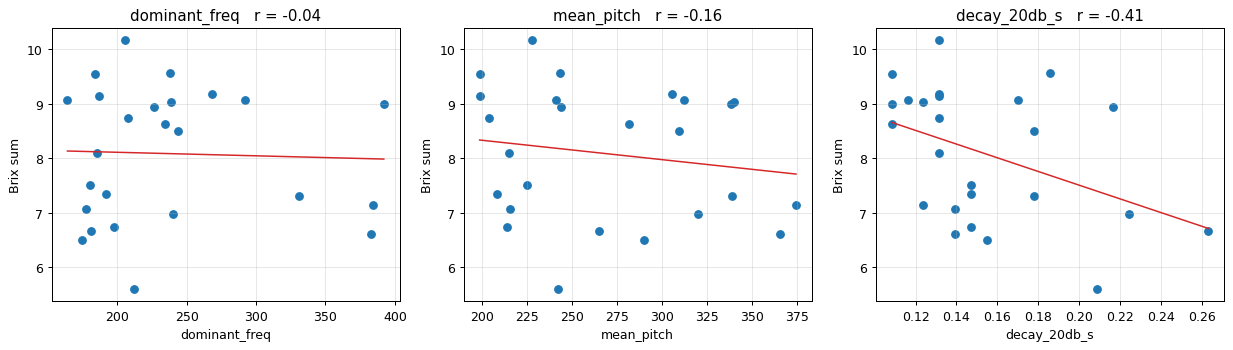

In [24]:
PREDICTED = ['dominant_freq', 'mean_pitch', 'decay_20db_s']
N_PERM = 10000

if audio_melon.empty:
    print('no audio - skipping')
else:
    d = feat_all.dropna(subset=['Brix sum'] + PREDICTED)
    y = d['Brix sum'].to_numpy(float)
    X = d[PREDICTED].to_numpy(float)

    r_obs = np.array([np.corrcoef(X[:, j], y)[0, 1] for j in range(X.shape[1])])

    rng = np.random.default_rng(0)
    perms = np.array([rng.permutation(y) for _ in range(N_PERM)])
    Xc = X - X.mean(axis=0)
    Pc = perms - perms.mean(axis=1, keepdims=True)
    r_null = (Pc @ Xc) / np.sqrt((Pc ** 2).sum(axis=1)[:, None] * (Xc ** 2).sum(axis=0)[None, :])

    max_null = np.abs(r_null).max(axis=1)
    res = pd.DataFrame({
        'feature': PREDICTED,
        'r': r_obs.round(3),
        'p_perm': [(np.abs(r_null[:, j]) >= abs(r_obs[j])).mean() for j in range(len(PREDICTED))],
        'p_family': [(max_null >= abs(r_obs[j])).mean() for j in range(len(PREDICTED))],
    }).sort_values('r', key=abs, ascending=False)

    print(f'{len(d)} melons with both Brix and a recording, {N_PERM} permutations')
    print('expected sign: negative for all three (softer flesh -> lower pitch, faster decay)\n')
    print(res.to_string(index=False))
    wrong = res[res.r > 0]
    if not wrong.empty:
        print('\nagainst prediction (positive r):', ', '.join(wrong.feature))

    fig, ax = plt.subplots(1, len(PREDICTED), figsize=(4.6 * len(PREDICTED), 4))
    for a, c in zip(np.atleast_1d(ax), PREDICTED):
        a.scatter(d[c], d['Brix sum'], s=36)
        b1, b0 = np.polyfit(d[c].to_numpy(float), y, 1)
        xs = np.linspace(d[c].min(), d[c].max(), 50)
        a.plot(xs, b1 * xs + b0, color='tab:red', lw=1.2)
        rr = float(np.corrcoef(d[c].to_numpy(float), y)[0, 1])
        a.set_xlabel(c); a.set_ylabel('Brix sum'); a.set_title(f'{c}   r = {rr:+.2f}')
        a.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

---
## 22. Write the training CSV
Step 20's `watermelon_features.csv` is the **inspection** table: everything, including diagnostics and all the raw Brix readings. It is not safe to train on as it stands. This step writes `watermelon_training.csv`, which is.

**The setup:** predict `brix_mean` (one number per melon) from every measured column — the 9 photo features and the 3 knock features — with `melon_id` carried along as a label, not an input.

What is deliberately *not* an input, and why:

| dropped | reason |
| --- | --- |
| `Name` | unique per melon, so a model can simply memorise it |
| `type` | the variety label. Excluded by choice: the model should predict from what was *measured*, not from which variety it is |
| `Brix top`, `Brix middle`, `Brix bottom` | `brix_mean` is their exact mean, so including them hands over the answer |
| `n_knocks`, `n_clips`, `duration_s`, `clip_duration_s` | describe how the recording was made, not the melon |
| `melon_id` | kept as a column for joining results back, but listed as the id, never a feature |

The leakage check is an `assert`, not a comment: the cell recomputes `mean(top, middle, bottom)` against `Brix sum` on every run and stops if they ever stop matching.

Column names are cleaned on the way out, so `field spot colour (b*)` becomes `field_spot_colour_b` and the file loads in anything.

**One thing to know about dropping `type`.** `stripe_width` is blank for every kinnaree melon by design, so *whether that cell is empty* still tells a model the variety, even with the label gone. The cell measures this and says so. If the variety must be invisible, drop `stripe_width` as well — it only has real values for the sonya melons anyway.

**Missing values are left as empty cells, deliberately.** With 25 rows, discarding a melon over one absent feature is expensive, and the right fix (impute, or use a model that handles gaps) belongs to the trainer. The cell reports complete rows both with and without `stripe_width`, since that column alone would otherwise disqualify every kinnaree. Set `DROP_INCOMPLETE = True` to keep only complete cases.

`watermelon_training_schema.json` is written alongside, listing the target, the id column, the feature names, and every dropped column with its reason — so the trainer reads the feature list from the schema rather than hardcoding it.

**About actually training on this.** 25 rows against 12 features is very little; expect to overfit, and judge nothing by fit on the training rows. Cross-validated error on a small feature set is the only meaningful number, and the three knock features are the ones with a mechanism behind them. The collinearity check matters here: `dominant_freq` and `mean_pitch` correlate at ~0.998, which is fine for a tree and bad for a linear model, so pick one of that pair.

In [25]:
import json

DROP_INCOMPLETE = False
TARGET = 'brix_mean'

parts = ['Brix top', 'Brix middle', 'Brix bottom']
gap = (feat_all[parts].mean(axis=1) - feat_all['Brix sum']).abs().max()
assert gap < 1e-6, (
    f'Brix sum is no longer the mean of {parts} (max difference {gap:.6g}).\n'
    f'Re-check which column is the target before training on this file.')
print(f'checked: Brix sum == mean{tuple(parts)} to {gap:.1e} - dropping the three components')

EXCLUDE = {
    'no':              'identifier (kept separately as melon_id, not a feature)',
    'Name':            'identifier - unique per melon, a model can memorise it',
    'type':            'variety label - excluded by choice; the model predicts from '
                       'what was measured, not from which variety it is',
    'Brix top':        'component of the target - including it leaks the answer',
    'Brix middle':     'component of the target - including it leaks the answer',
    'Brix bottom':     'component of the target - including it leaks the answer',
    'Brix sum':        'this is the target itself',
    'n_knocks':        'diagnostic: how many taps were detected, not a melon property',
    'n_clips':         'diagnostic: how many recordings exist',
    'duration_s':      'diagnostic: length of the analysis window',
    'clip_duration_s': 'diagnostic: how long you recorded for',
    'rind_px':         'scale artefact: pixel area depends on camera distance',
    'n_views':         'diagnostic: how many usable photos this melon had',
    'stripe_width_sonya_only':
                       'blank for all 14 kinnaree melons (dark rind, no stripes found). Whether it is blank reveals the variety, so keeping it would leak type back in after type was dropped.',
}

def snake(name):
    s = name.strip().lower().replace('*', '').replace('%', 'pct')
    return re.sub(r'[^a-z0-9]+', '_', s).strip('_')

train = pd.DataFrame({'melon_id': feat_all['no'].astype(int),
                      TARGET: feat_all['Brix sum'].astype(float)})
feature_cols = []
for col in feat_all.columns:
    if col in EXCLUDE:
        continue
    name = snake(col)
    train[name] = pd.to_numeric(feat_all[col], errors='coerce')
    feature_cols.append(name)

train = train[['melon_id', TARGET] + feature_cols].sort_values('melon_id')
train = train.dropna(subset=[TARGET])

core_cols = [c for c in feature_cols if c != 'stripe_width_sonya_only']
complete = train[feature_cols].notna().all(axis=1)
complete_core = train[core_cols].notna().all(axis=1)
print(f'\n{len(train)} melons, {len(feature_cols)} features predicting {TARGET}')
print(f'  rows with every feature present   : {int(complete.sum())}')
print(f'  ... ignoring stripe_width         : {int(complete_core.sum())}')
gaps = train[feature_cols].isna().sum()
if gaps.any():
    print('missing values per feature:')
    for k, v in gaps[gaps > 0].items():
        note = '  (blank for kinnaree by design)' if k.startswith('stripe_width') else ''
        print(f'  {k:24s} {v:3d} missing{note}')
if DROP_INCOMPLETE:
    kept = train[complete]
    if len(kept) < 10:
        print(f'\nWARNING: DROP_INCOMPLETE leaves only {len(kept)} of {len(train)} rows. '
              f'stripe_width is blank for all kinnaree melons, so it is the likely '
              f'cause - dropping that one column keeps {int(complete_core.sum())} rows.')
    train = kept
    print(f'DROP_INCOMPLETE is on -> kept {len(train)} rows')

variety_note = None
if 'type' in feat_all and 'stripe_width_sonya_only' in feature_cols:
    by_var = (train.set_index('melon_id')['stripe_width_sonya_only'].isna()
              .groupby(feat_all.set_index('no')['type']).mean())
    if by_var.max() - by_var.min() > 0.5:
        variety_note = ('stripe_width is blank for whole varieties, so whether it is blank '
                        'still reveals type even though type itself was dropped')
        print(f'\nnote: {variety_note}. Fraction blank by variety:')
        print('  ' + by_var.round(2).to_string().replace('\n', '\n  '))
        print('  -> drop stripe_width too if the model must not know the variety at all')

corr = train[feature_cols].dropna(axis=1, how='all').corr().abs()
pairs = [(a, b, corr.loc[a, b]) for i, a in enumerate(corr.columns)
         for b in corr.columns[i + 1:] if corr.loc[a, b] > 0.95]
if pairs:
    print('\nnear-duplicate features (|r| > 0.95) - keep one of each pair for a linear model:')
    for a, b, r in sorted(pairs, key=lambda t: -t[2]):
        print(f'  {a} <-> {b}   r = {r:.3f}')

TRAIN_CSV = Path('watermelon_training.csv')
SCHEMA_JSON = Path('watermelon_training_schema.json')
train.to_csv(TRAIN_CSV, index=False)
SCHEMA_JSON.write_text(json.dumps({
    'task': 'regression',
    'target': TARGET,
    'target_note': "the sheet's 'Brix sum' column, which is the mean of the top/middle/bottom readings",
    'id_column': 'melon_id',
    'features': feature_cols,
    'n_rows': int(len(train)),
    'n_complete_rows': int(complete.sum()),
    'n_complete_rows_ignoring_stripe_width': int(complete_core.sum()),
    'missing_allowed': not DROP_INCOMPLETE,
    'excluded': EXCLUDE,
    'mechanism_backed_features': ['dominant_freq', 'mean_pitch', 'decay_20db_s'],
    'near_duplicate_pairs': [[a, b, round(float(r), 4)] for a, b, r in pairs],
    'caveats': [c for c in [
        'n=25: judge models by cross-validated error, never by training-set fit.',
        'dominant_freq and mean_pitch estimate the same resonant frequency.',
        'frequency features are confounded by melon size; no mass was recorded.',
        variety_note,
    ] if c],
}, indent=2), encoding='utf-8')

print(f'\nwrote {TRAIN_CSV.resolve()}')
print(f'wrote {SCHEMA_JSON.resolve()}')
print(f'\n{TARGET} <- {len(feature_cols)} features:')
print('  ' + '\n  '.join(feature_cols))
train.round(3)

checked: Brix sum == mean('Brix top', 'Brix middle', 'Brix bottom') to 3.3e-10 - dropping the three components

25 melons, 13 features predicting brix_mean
  rows with every feature present   : 19
  ... ignoring stripe_width         : 19
missing values per feature:
  field_spot_b               6 missing
  field_spot_l               6 missing
  field_spot_a               6 missing

wrote D:\Watermelon\watermelon_training.csv
wrote D:\Watermelon\watermelon_training_schema.json

brix_mean <- 13 features:
  field_spot_area_pct
  webbing
  rind_gloss
  shape_uniformity
  bee_sting_density
  spot_present
  field_spot_b
  field_spot_l
  field_spot_a
  rind_b
  mean_pitch
  dominant_freq
  decay_20db_s


,melon_id,brix_mean,field_spot_area_pct,webbing,rind_gloss,shape_uniformity,bee_sting_density,spot_present,field_spot_b,field_spot_l,field_spot_a,rind_b,mean_pitch,dominant_freq,decay_20db_s
0,1,6.667,0.000,0.161,0.396,1.299,2.691,0,NaN,NaN,NaN,12.5,264.890,181.350,0.263
1,2,7.500,2.144,0.292,0.753,1.351,0.163,1,43.673,51.459,-7.341,18.5,225.004,180.016,0.147
2,3,7.067,18.103,0.516,0.835,1.264,1.218,1,45.284,51.963,-10.847,14.0,215.280,177.349,0.139
3,4,8.500,0.000,0.227,0.448,1.336,0.243,0,NaN,NaN,NaN,13.0,309.637,244.022,0.178
4,5,6.500,17.812,0.282,0.416,1.182,3.937,1,49.314,57.211,-11.514,14.5,289.788,174.683,0.155
5,6,10.167,0.573,0.243,1.608,1.485,2.774,1,41.810,66.314,-12.125,9.0,227.685,205.352,0.132
6,7,6.733,15.632,1.505,1.236,1.318,0.781,1,46.816,51.418,-5.211,8.0,213.450,197.351,0.147
7,8,9.133,3.878,0.181,0.547,1.233,4.576,1,46.004,52.292,-13.435,10.0,198.435,186.684,0.132
8,9,9.167,16.130,0.747,2.238,1.322,1.203,1,48.583,61.675,-3.934,11.0,305.719,268.024,0.132
9,10,7.133,16.001,0.358,0.702,1.252,0.791,1,46.631,55.637,-11.150,12.0,374.491,384.035,0.124


## Limits to remember
**Photos**
* Photos had no colour card, and lighting varied, so colour and gloss are only comparable roughly.
* Bee-sting counts include some false positives from speckled rind.
* Melon 6 has only 3 usable side views; melon 19 had no ID photo, so its identity was inferred.

**Knock sounds**
* **Frequency is confounded by melon size.** A bigger melon rings lower regardless of ripeness. Acoustic firmness is normally measured as roughly *f*²*m*^⅔, and there is no mass column here, so `dominant_freq` and `mean_pitch` mix "soft" with "big". Weighing the melons is the single cheapest improvement available.
* **`dominant_freq` and `mean_pitch` are one measurement, not two.** They estimate the same resonant frequency by different means. Step 19 prints their agreement as a check; treat a strong result on both as one finding.
* **`decay_20db_s` saturates at the window length.** If a tap's window is cut short by the next tap, the decay is reported as the window length and the true value is longer. Step 19 counts how many recordings this affected.
* **Melon numbers come from filenames, not from the audio.** A misnamed file silently attaches one melon's sound to another melon's row — the mapping printed in step 19 is the only check on this.
* **Loudness was deliberately not used.** Each tap is peak-normalised, so how hard you hit and how close the microphone was do not leak into the features. The cost is that genuine differences in loudness are discarded too.
* **25 melons, three features.** Honest, but small. A result here is a hypothesis that survived one test, not an established effect — confirm it on melons that were not used to find it.
* Lossy recordings (`.m4a`) alter high-frequency content slightly compared with WAV; `dominant_freq` and decay were unaffected in my check. Record WAV where you can.
* The MFCCs, deltas and other spectral summaries from the original sketch were removed deliberately: ~50 features against 25 melons guarantees a convincing-looking winner by luck. Revisit that only with more melons.

**The training file**
* `watermelon_features.csv` is for reading; `watermelon_training.csv` is for training. Only the second one has the leakage columns removed — `Brix sum` is the exact mean of the three Brix readings, so a model given all four learns the arithmetic and nothing else.
* `Name` and `type` are both excluded, so the model predicts from measurements alone. But `stripe_width` is blank for every kinnaree melon by design, so its missingness still reveals the variety; drop that column too if the variety must be invisible.
* Missing values are left blank on purpose. Requiring complete rows would discard every kinnaree melon, for the `stripe_width` reason above.
* Read the feature list from `watermelon_training_schema.json` rather than hardcoding it, so the two cannot drift apart.
* With 25 rows, training-set accuracy is meaningless. Cross-validated error on a small feature set is the only number worth quoting.

---
## 23. The cue to column contract

One column per cue, fixed here and written to `cues.json` so the Trainer reads
the same mapping rather than redefining it.

**Cue 3 (sound) is two features, not one.** `dominant_freq` and `mean_pitch` both
estimate the resonant frequency - step 19 measured their agreement at r = +0.83,
so they are two readings of one quantity. `decay_20db_s` measures damping, which
is physically separate. So the sound cue splits into **pitch** and **decay**, and
`mean_pitch` represents pitch: it is magnitude-weighted and follows the ringing
tone, where `dominant_freq` is a raw argmax that can lock onto the striker click.

**Cues 2 and 6 have no column.** No mass was recorded, so "heavy for its size"
cannot be tested. Stripe width is blank for all 14 kinnaree melons, and whether
it is blank reveals the variety, so keeping it would leak `type` back in.

This leaves **6 cues in 7 columns**. Choosing `mean_pitch` over `dominant_freq`
affects no hypothesis test - the model feature sets are not tests. The per-cue
verdicts for every cue, sound included, are in step 26, corrected across all 7
columns.

In [26]:
import json

CUES = {
    # cue: (column, folk direction: +1 = higher is sweeter)
    'field_spot': ('field_spot_area_pct', +1),
    'webbing':    ('webbing',             +1),
    'gloss':      ('rind_gloss',          -1),
    'shape':      ('shape_uniformity',    -1),
    'bee_stings': ('bee_sting_density',   +1),
    'sound':      (['mean_pitch', 'decay_20db_s'], -1),
}
PRIMARY = ['field_spot', 'sound', 'webbing']
TARGET  = 'brix_mean'

train = pd.read_csv('watermelon_training.csv')

cols, missing = [], []
for cue, (c, _) in CUES.items():
    for col in ([c] if isinstance(c, str) else c):
        cols.append(col)
        if col not in train.columns:
            missing.append(f'{cue}: {col} not in watermelon_training.csv')
        elif train[col].isna().any():
            missing.append(f'{cue}: {col} has {int(train[col].isna().sum())} NaN')
assert not missing, 'cue contract broken:\n  ' + '\n  '.join(missing)

print(f'{len(train)} melons, {len(CUES)} cues in {len(cols)} columns, no NaN\n')
print(f"{'cue':12s} {'column':22s} {'folk':>5s} {'rho':>7s}  direction")
print('-' * 62)
for cue, (c, d) in CUES.items():
    for col in ([c] if isinstance(c, str) else c):
        rho = train[col].corr(train[TARGET], method='spearman')
        if abs(rho) < 0.1:
            verdict = 'flat'
        else:
            verdict = 'as claimed' if (rho > 0) == (d > 0) else 'OPPOSITE'
        star = ' *' if cue in PRIMARY else '  '
        print(f'{cue:12s}{star}{col:22s} {d:+5d} {rho:+7.3f}  {verdict}')
print('\n* = primary cue.  Raw Spearman, NOT controlled for variety and NOT')
print('  Holm-corrected - these are previews; the verdicts are in step 26.')

mae_base = (train[TARGET] - train[TARGET].mean()).abs().mean()
print(f'\nmean-baseline MAE {mae_base:.3f} degBrix   ->   15% target {0.85*mae_base:.3f}')

COMPLETE = [c for c in train.columns
            if c not in ('melon_id', TARGET) and not train[c].isna().any()]
Path('cues.json').write_text(json.dumps({
    'target': TARGET,
    'id_column': 'melon_id',
    'cues': {k: {'columns': [v[0]] if isinstance(v[0], str) else v[0],
                 'folk_direction': v[1],
                 'primary': k in PRIMARY} for k, v in CUES.items()},
    'absent_cues': {
        'weight':       'no mass recorded; "heavy for its size" is untestable',
        'stripe_width': 'blank for all 14 kinnaree melons; blankness reveals variety',
    },
    'all_complete_columns': COMPLETE,
    'mean_baseline_mae': round(float(mae_base), 4),
    'target_mae_15pct': round(float(0.85 * mae_base), 4),
    'n_melons': int(len(train)),
}, indent=2), encoding='utf-8')
print(f'\nwrote cues.json  ({len(COMPLETE)} complete columns available)')

25 melons, 6 cues in 7 columns, no NaN

cue          column                  folk     rho  direction
--------------------------------------------------------------
field_spot   *field_spot_area_pct       +1  -0.206  OPPOSITE
webbing      *webbing                   +1  +0.269  as claimed
gloss         rind_gloss                -1  +0.544  OPPOSITE
shape         shape_uniformity          -1  +0.076  flat
bee_stings    bee_sting_density         +1  -0.083  flat
sound        *mean_pitch                -1  -0.211  as claimed
sound        *decay_20db_s              -1  -0.446  as claimed

* = primary cue.  Raw Spearman, NOT controlled for variety and NOT
  Holm-corrected - these are previews; the verdicts are in step 26.

mean-baseline MAE 1.080 degBrix   ->   15% target 0.918

wrote cues.json  (10 complete columns available)


---
# Part 3: does each cue matter?
Two methods, one question each:

| step | method | question it answers |
| --- | --- | --- |
| 24 | **Spearman correlation** | How strongly does this cue move with sweetness, and in which direction? |
| 25 | **Permutation test** | Could a correlation that strong be luck? |

The cues tested are exactly the 7 columns fixed in `cues.json` (step 23), so the list was chosen before looking at any results. Everything is saved to `results/` in step 26.

## 24. Spearman correlation
Sort the 25 melons by the cue and give them ranks 1 to 25. Then do the same by Brix. Spearman's **ρ** (rho) measures how well the two rankings agree:
* **+1**: the higher the cue, the sweeter, every time.
* **−1**: the higher the cue, the *less* sweet, every time.
* **0**: no relationship.

It uses ranks rather than raw values, so a single extreme melon (one with a huge field spot, say) cannot drag the result. With only 25 melons, that protection matters.

In [2]:
import json
from scipy import stats

CUE_SPEC = json.loads(Path('cues.json').read_text(encoding='utf-8'))
data = pd.read_csv('watermelon_features.csv')
Y = 'Brix sum'

FEATS, FOLK, CUE_OF = [], {}, {}
for cue, spec in CUE_SPEC['cues'].items():
    for col in spec['columns']:
        FEATS.append(col); FOLK[col] = spec['folk_direction']; CUE_OF[col] = cue

d = data[FEATS + [Y, 'type']].dropna()
y = d[Y].to_numpy(float)
rho = {f: stats.spearmanr(d[f], y)[0] for f in FEATS}

res = pd.DataFrame({'cue': [CUE_OF[f] for f in FEATS],
                    'spearman_rho': [rho[f] for f in FEATS]}, index=FEATS)
print(f'{len(d)} melons, {len(FEATS)} cue columns')
res.round(3)

25 melons, 7 cue columns


,cue,spearman_rho
field_spot_area_pct,field_spot,-0.206
webbing,webbing,0.269
rind_gloss,gloss,0.544
shape_uniformity,shape,0.076
bee_sting_density,bee_stings,-0.083
mean_pitch,sound,-0.211
decay_20db_s,sound,-0.446


## 25. Permutation test: could it be luck?
If a cue had nothing to do with sweetness, it would not matter which melon got which Brix value. So we **shuffle the Brix column** at random, recompute every ρ, and repeat 10,000 times. That shows what correlations pure chance produces.

Two p-values come out of the same shuffles:
* **`p_single`**: how often chance gives *this* cue a ρ at least as strong as the real one. This is the right number if it were the only cue we tested.
* **`p_best_of_7`**: how often chance gives the *strongest of all 7 cues* a ρ that strong. We tested 7 cues and the eye goes to the strongest one, so this is the honest number to quote. It is always larger than `p_single`.

Below 0.05 means: chance does this less than 1 time in 20.

In [3]:
N_PERM = 10000
rng = np.random.default_rng(42)

R = d[FEATS].rank().to_numpy(float)
R = (R - R.mean(0)) / np.linalg.norm(R - R.mean(0), axis=0)
ry = stats.rankdata(y)
obs = np.array([rho[f] for f in FEATS])

null = np.empty((N_PERM, len(FEATS)))
for i in range(N_PERM):
    s = rng.permutation(ry)
    s = (s - s.mean()) / np.linalg.norm(s - s.mean())
    null[i] = s @ R
best = np.abs(null).max(axis=1)

res['p_single'] = [(np.abs(null[:, j]) >= abs(obs[j])).mean() for j in range(len(FEATS))]
res['p_best_of_7'] = [(best >= abs(obs[j])).mean() for j in range(len(FEATS))]
res.round(3)

,cue,spearman_rho,p_single,p_best_of_7
field_spot_area_pct,field_spot,-0.206,0.311,0.926
webbing,webbing,0.269,0.193,0.758
rind_gloss,gloss,0.544,0.004,0.036
shape_uniformity,shape,0.076,0.710,1.000
bee_sting_density,bee_stings,-0.083,0.690,1.000
mean_pitch,sound,-0.211,0.310,0.916
decay_20db_s,sound,-0.446,0.026,0.169


## 26. Verdict, and save the results
The rule, which we chose ourselves:
* **supported**: `p_best_of_7` below 0.05. It beats chance even after allowing for having tested 7 cues.
* **suggestive**: only `p_single` is below 0.05. It would count if it were the only cue tested, but not once we allow for 7.
* **no evidence**: neither.

`folk` says whether the sign agrees with the folk claim in `cues.json`. A cue can be **supported** and still go the **opposite** way to the folklore: it carries information, but the folk rule has it backwards.

This writes:
* `results/cue_results.csv`: the table below.
* `results/cue_scatter.png`: one plot per cue (circles = sonya, triangles = kinnaree), to check by eye that no single melon or variety drives a result.

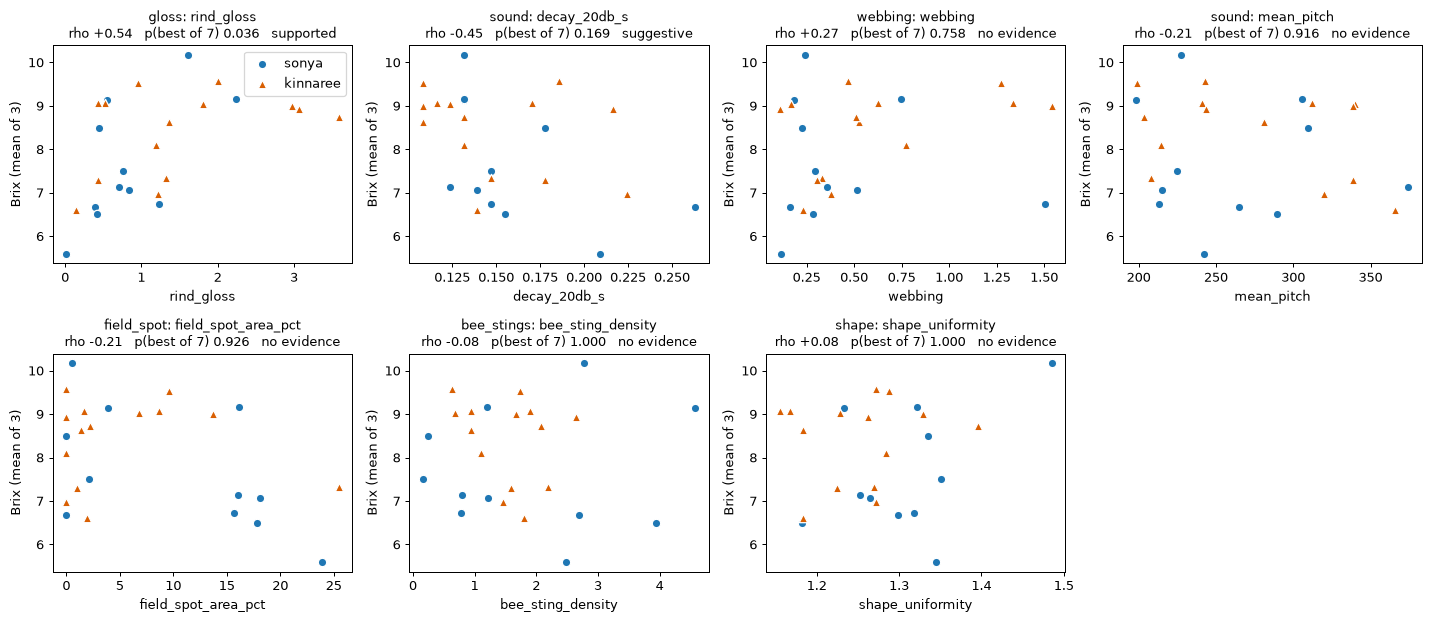

wrote C:\Users\janep\AppData\Local\Temp\claude\C--Users-janep-OneDrive--------Work-neo-Watermelon\9135671c-a7ee-451c-a3d2-e0b529935416\scratchpad\run2\results\cue_results.csv
wrote C:\Users\janep\AppData\Local\Temp\claude\C--Users-janep-OneDrive--------Work-neo-Watermelon\9135671c-a7ee-451c-a3d2-e0b529935416\scratchpad\run2\results\cue_scatter.png


,cue,spearman_rho,p_single,p_best_of_7,verdict,folk
rind_gloss,gloss,0.544,0.004,0.036,supported,OPPOSITE
decay_20db_s,sound,-0.446,0.026,0.169,suggestive,as claimed
webbing,webbing,0.269,0.193,0.758,no evidence,as claimed
mean_pitch,sound,-0.211,0.310,0.916,no evidence,as claimed
field_spot_area_pct,field_spot,-0.206,0.311,0.926,no evidence,OPPOSITE
bee_sting_density,bee_stings,-0.083,0.690,1.000,no evidence,flat
shape_uniformity,shape,0.076,0.710,1.000,no evidence,flat


In [4]:
def verdict(r):
    if r.p_best_of_7 < 0.05: return 'supported'
    if r.p_single < 0.05: return 'suggestive'
    return 'no evidence'

def folk(f):
    if abs(rho[f]) < 0.1: return 'flat'
    return 'as claimed' if (rho[f] > 0) == (FOLK[f] > 0) else 'OPPOSITE'

res['verdict'] = res.apply(verdict, axis=1)
res['folk'] = [folk(f) for f in res.index]
res = res.sort_values('p_single')

OUT = Path('results'); OUT.mkdir(exist_ok=True)
res.round(4).to_csv(OUT / 'cue_results.csv', index_label='column')

fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
style = {'sonya': ('#1f77b4', 'o'), 'kinnaree': ('#d95f02', '^')}
for ax, f in zip(axes, res.index):
    for v, (c, mk) in style.items():
        g = d[d.type == v]
        ax.scatter(g[f], g[Y], c=c, marker=mk, s=45, label=v, edgecolor='white')
    r = res.loc[f]
    ax.set_title(f'{r.cue}: {f}\nrho {r.spearman_rho:+.2f}   p(best of 7) {r.p_best_of_7:.3f}   {r.verdict}', fontsize=10)
    ax.set_xlabel(f); ax.set_ylabel('Brix (mean of 3)')
axes[0].legend()
for ax in axes[len(FEATS):]: ax.axis('off')
plt.tight_layout(); fig.savefig(OUT / 'cue_scatter.png', dpi=110); plt.show()

print('wrote', (OUT / 'cue_results.csv').resolve())
print('wrote', (OUT / 'cue_scatter.png').resolve())
res.round(3)

**How to report this.** With 25 melons, even a "supported" cue is a pattern worth testing on more melons, not a proven rule. "No cue clearly predicts Brix at this sample size" is a legitimate finding for the project.

**Left out on purpose:**
* **Variety.** These tests pool sonya and kinnaree. If one variety were both sweeter and different-looking, a cue could correlate with Brix only because it separates the varieties. The scatter plot marks the two varieties so you can check this by eye. The Brix difference between the two varieties was not significant here (8.4 vs 7.7 °Brix).
* **Weight and stripe width.** Weight was never recorded, and stripe width is blank for every kinnaree melon (see `absent_cues` in `cues.json`).